**<font color='yellow' size="6">Esophageal Cancer Classification Using YOLOV8 for WLI images</font><br>**

In [ ]:
!nvidia-smi

Tue Aug 20 03:25:07 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   35C    P8               9W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
# Directory for your WLI data
DATA_DIR_wli_reference = '/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/'

In [ ]:
from IPython.display import Image, display

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.5 MB/s eta 0:00:00
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_curand_cu12-10.3.2.106-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cusolver_cu12-11.4.5.107-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cusparse_cu12-12.1.0.106-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_nccl_cu12-2.20.5-py3-none-manylinux2014_x86_64.

<font color ='yellow' size='4'> Training for YOLOv8x and YOLOv8n for 300 epochs with 100 as a pause value</font>

In [ ]:
import os
from ultralytics import YOLO

# Directory for your WLI data
DATA_DIR_wli = '/content/drive/MyDrive/EC/WLI_split/'

# List of YOLOv8 model versions you want to try
model_versions = ["yolov8x-cls.pt", "yolov8n-cls.pt"]  # YOLOv8 'x' and 'n' versions

# Initialize variables to track the best model
best_model = None
best_accuracy = 0

# Train each model version
for model_version in model_versions:
    model = YOLO(model_version)  # Load the pretrained model

    # Train in increments of 100 epochs, up to 300 epochs
    for i in range(0, 300, 100):
        # Specify a unique directory for each 100-epoch segment
        run_name = f"train_{model_version.split('.')[0]}_{i+100}_epochs"
        results = model.train(
            data=DATA_DIR_wli,
            epochs=100,           # Train for 100 epochs
            imgsz=640,            # Image size
            batch=16,             # Batch size
            augment=True,         # Enable augmentation
            flipud=0.5,           # Vertical flip with 50% probability
            fliplr=0.5,           # Horizontal flip with 50% probability
            degrees=10,           # Rotate images by up to 10 degrees
            scale=0.5,            # Scale images by up to 50%
            translate=0.1,        # Translate images by 10% in x and y directions
            lr0=0.001,            # Initial learning rate
            save=True,            # Save the model checkpoints
            project="runs",       # Save directory
            name=run_name         # Unique name for the run
        )

        # Evaluate the model on the validation set
        val_results = model.val(data=DATA_DIR_wli, imgsz=640, batch=16)

        # Track accuracy or any other metric
        current_accuracy = val_results.top1  # Access accuracy directly from val_results
        # You can also access top5 accuracy using val_results.top5

        if current_accuracy > best_accuracy:
            best_accuracy = current_accuracy
            best_model = model_version

        # Log the results
        print(f"Model: {model_version}, Epochs: {i + 100}, Accuracy: {current_accuracy}")

# Output the best model after all training
print(f"Best model: {best_model} with accuracy: {best_accuracy}")

Ultralytics YOLOv8.2.78 🚀 Python-3.10.12 torch-2.3.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=classify, mode=train, model=yolov8x-cls.pt, data=/content/drive/MyDrive/EC/WLI_split/, epochs=100, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=runs, name=train_yolov8x-cls_100_epochs3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=True, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, sav

train: Scanning /content/drive/MyDrive/EC/WLI_split/train... 751 images, 0 corrupt: 100%|██████████| 751/751 [00:00<?, ?it/s]
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
val: Scanning /content/drive/MyDrive/EC/WLI_split/val... 214 images, 0 corrupt: 100%|██████████| 214/214 [00:00<?, ?it/s]


optimizer: 'optimizer=auto' found, ignoring 'lr0=0.001' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 50 weight(decay=0.0), 51 weight(decay=0.0005), 51 bias(decay=0.0)
TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs/train_yolov8x-cls_100_epochs3
Starting training for 100 epochs...

      Epoch    GPU_mem       loss  Instances       Size


      1/100      10.4G     0.9141         15        640: 100%|██████████| 47/47 [00:09<00:00,  4.91it/s]
               classes   top1_acc   top5_acc: 100%|██████████| 7/7 [00:00<00:00, 12.10it/s]

                   all      0.766          1



      Epoch    GPU_mem       loss  Instances       Size


... (1,891 outputs left out)

               classes   top1_acc   top5_acc:  71%|███████▏  | 10/14 [00:02<00:00,  5.09it/s]

WARNING ⚠️ ClassificationModel does not support 'augment=True' prediction. Reverting to single-scale prediction.
WARNING ⚠️ ClassificationModel does not support 'augment=True' prediction. Reverting to single-scale prediction.
WARNING ⚠️ ClassificationModel does not support 'augment=True' prediction. Reverting to single-scale prediction.
WARNING ⚠️ ClassificationModel does not support 'augment=True' prediction. Reverting to single-scale prediction.


               classes   top1_acc   top5_acc: 100%|██████████| 14/14 [00:02<00:00,  6.02it/s]


                   all      0.958          1
Speed: 0.8ms preprocess, 0.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/train_yolov8n-cls_300_epochs2
Model: yolov8n-cls.pt, Epochs: 300, Accuracy: 0.9579439163208008
Best model: yolov8x-cls.pt with accuracy: 0.9579439163208008


**save the run folder**

In [ ]:
!scp -r /content/runs '/content/drive/MyDrive/EC/WLI_split/'



---



---



---



<font color='yellow' size='6'> Validation Accuracy of the 300th epochs </font>

**best.pt for the 300th epochs of YOLOv8x**

In [ ]:
!yolo task=classify mode=val model=/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8x-cls_300_epochs/weights/best.pt data={DATA_DIR_wli_reference}

Ultralytics YOLOv8.2.79 🚀 Python-3.10.12 torch-2.3.1+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8x-cls summary (fused): 133 layers, 56,127,043 parameters, 0 gradients, 153.8 GFLOPs
train: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/train... found 456 images in 3 classes ✅ 
val: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... found 214 images in 3 classes ✅ 
test: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... found 109 images in 3 classes ✅ 
val: Scanning /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... 214 images, 0 corrupt: 100% 214/214 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc:   7% 1/14 [00:58<12:41, 58.57s/it]Downloading https://ultralytics.com/assets/Arial.ttf to '/root/.config/Ultralytics/Arial.ttf'...

100% 755k/755k [00:00<00:00, 89.1MB/s]
               classes   top1_acc   top5_acc: 100% 14/14 [12:23<00:00, 53.07s/it]
                   all      0.921          1
Speed: 0.0ms preprocess, 3040.9ms inference, 0.0ms 

**best.pt for the 300th epochs of YOLOv8n for the validation images**

In [ ]:
!yolo task=classify mode=val model=/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt data={DATA_DIR_wli_reference}

Ultralytics YOLOv8.2.79 🚀 Python-3.10.12 torch-2.3.1+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8n-cls summary (fused): 73 layers, 1,438,723 parameters, 0 gradients, 3.3 GFLOPs
train: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/train... found 456 images in 3 classes ✅ 
val: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... found 214 images in 3 classes ✅ 
test: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... found 109 images in 3 classes ✅ 
val: Scanning /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... 214 images, 0 corrupt: 100% 214/214 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc: 100% 14/14 [00:35<00:00,  2.56s/it]
                   all      0.958          1
Speed: 0.0ms preprocess, 133.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val2
💡 Learn more at https://docs.ultralytics.com/modes/val


**yolov8x**

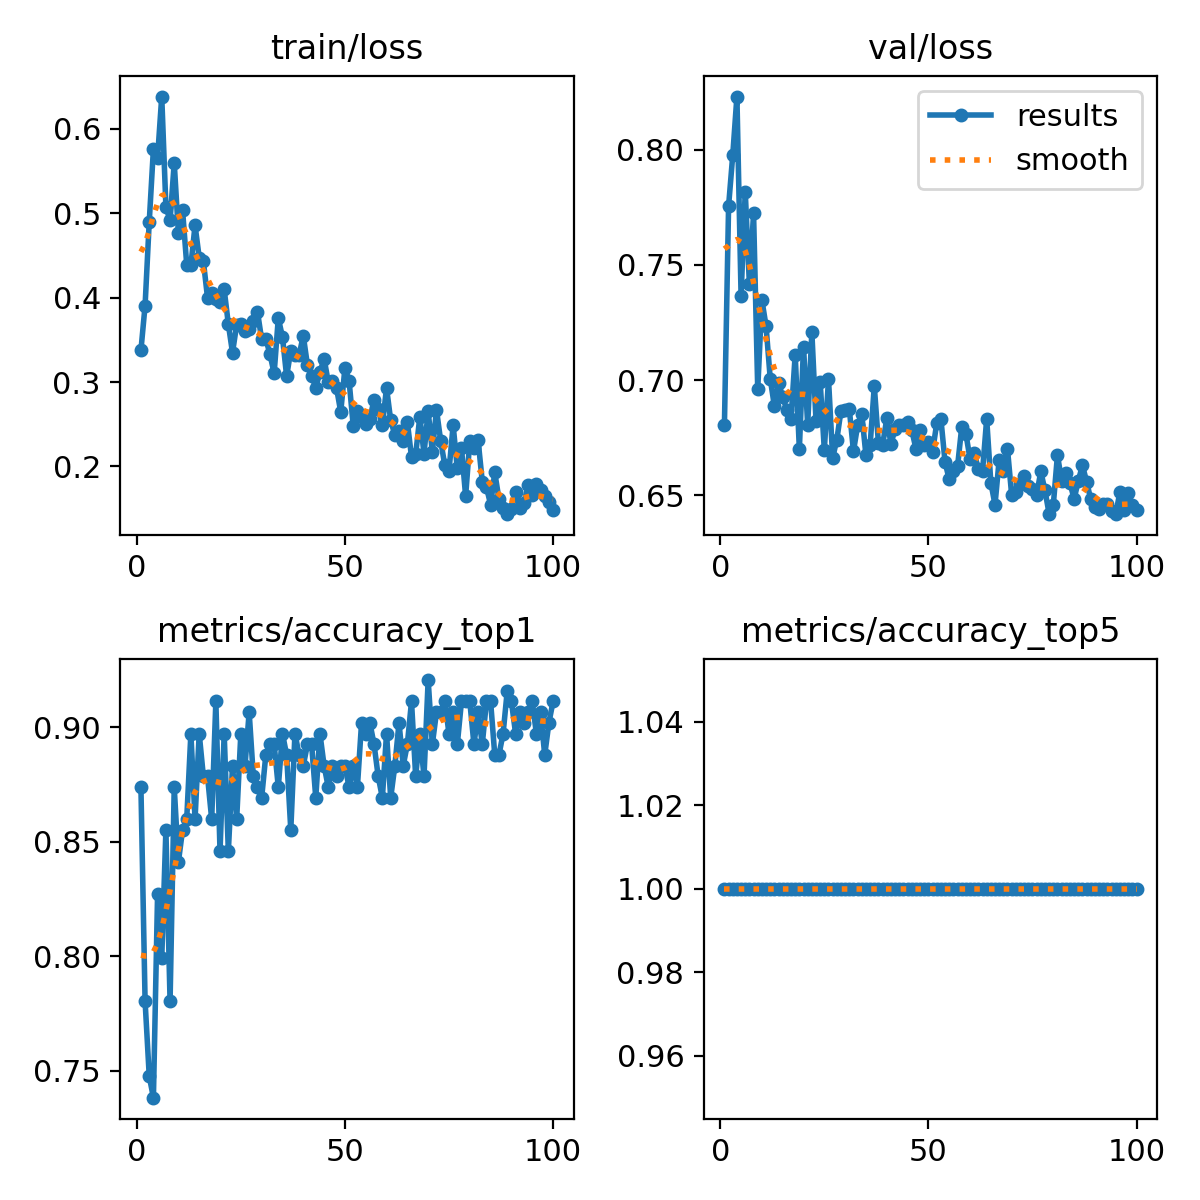

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8x-cls_300_epochs/results.png', width=1000, height=800)

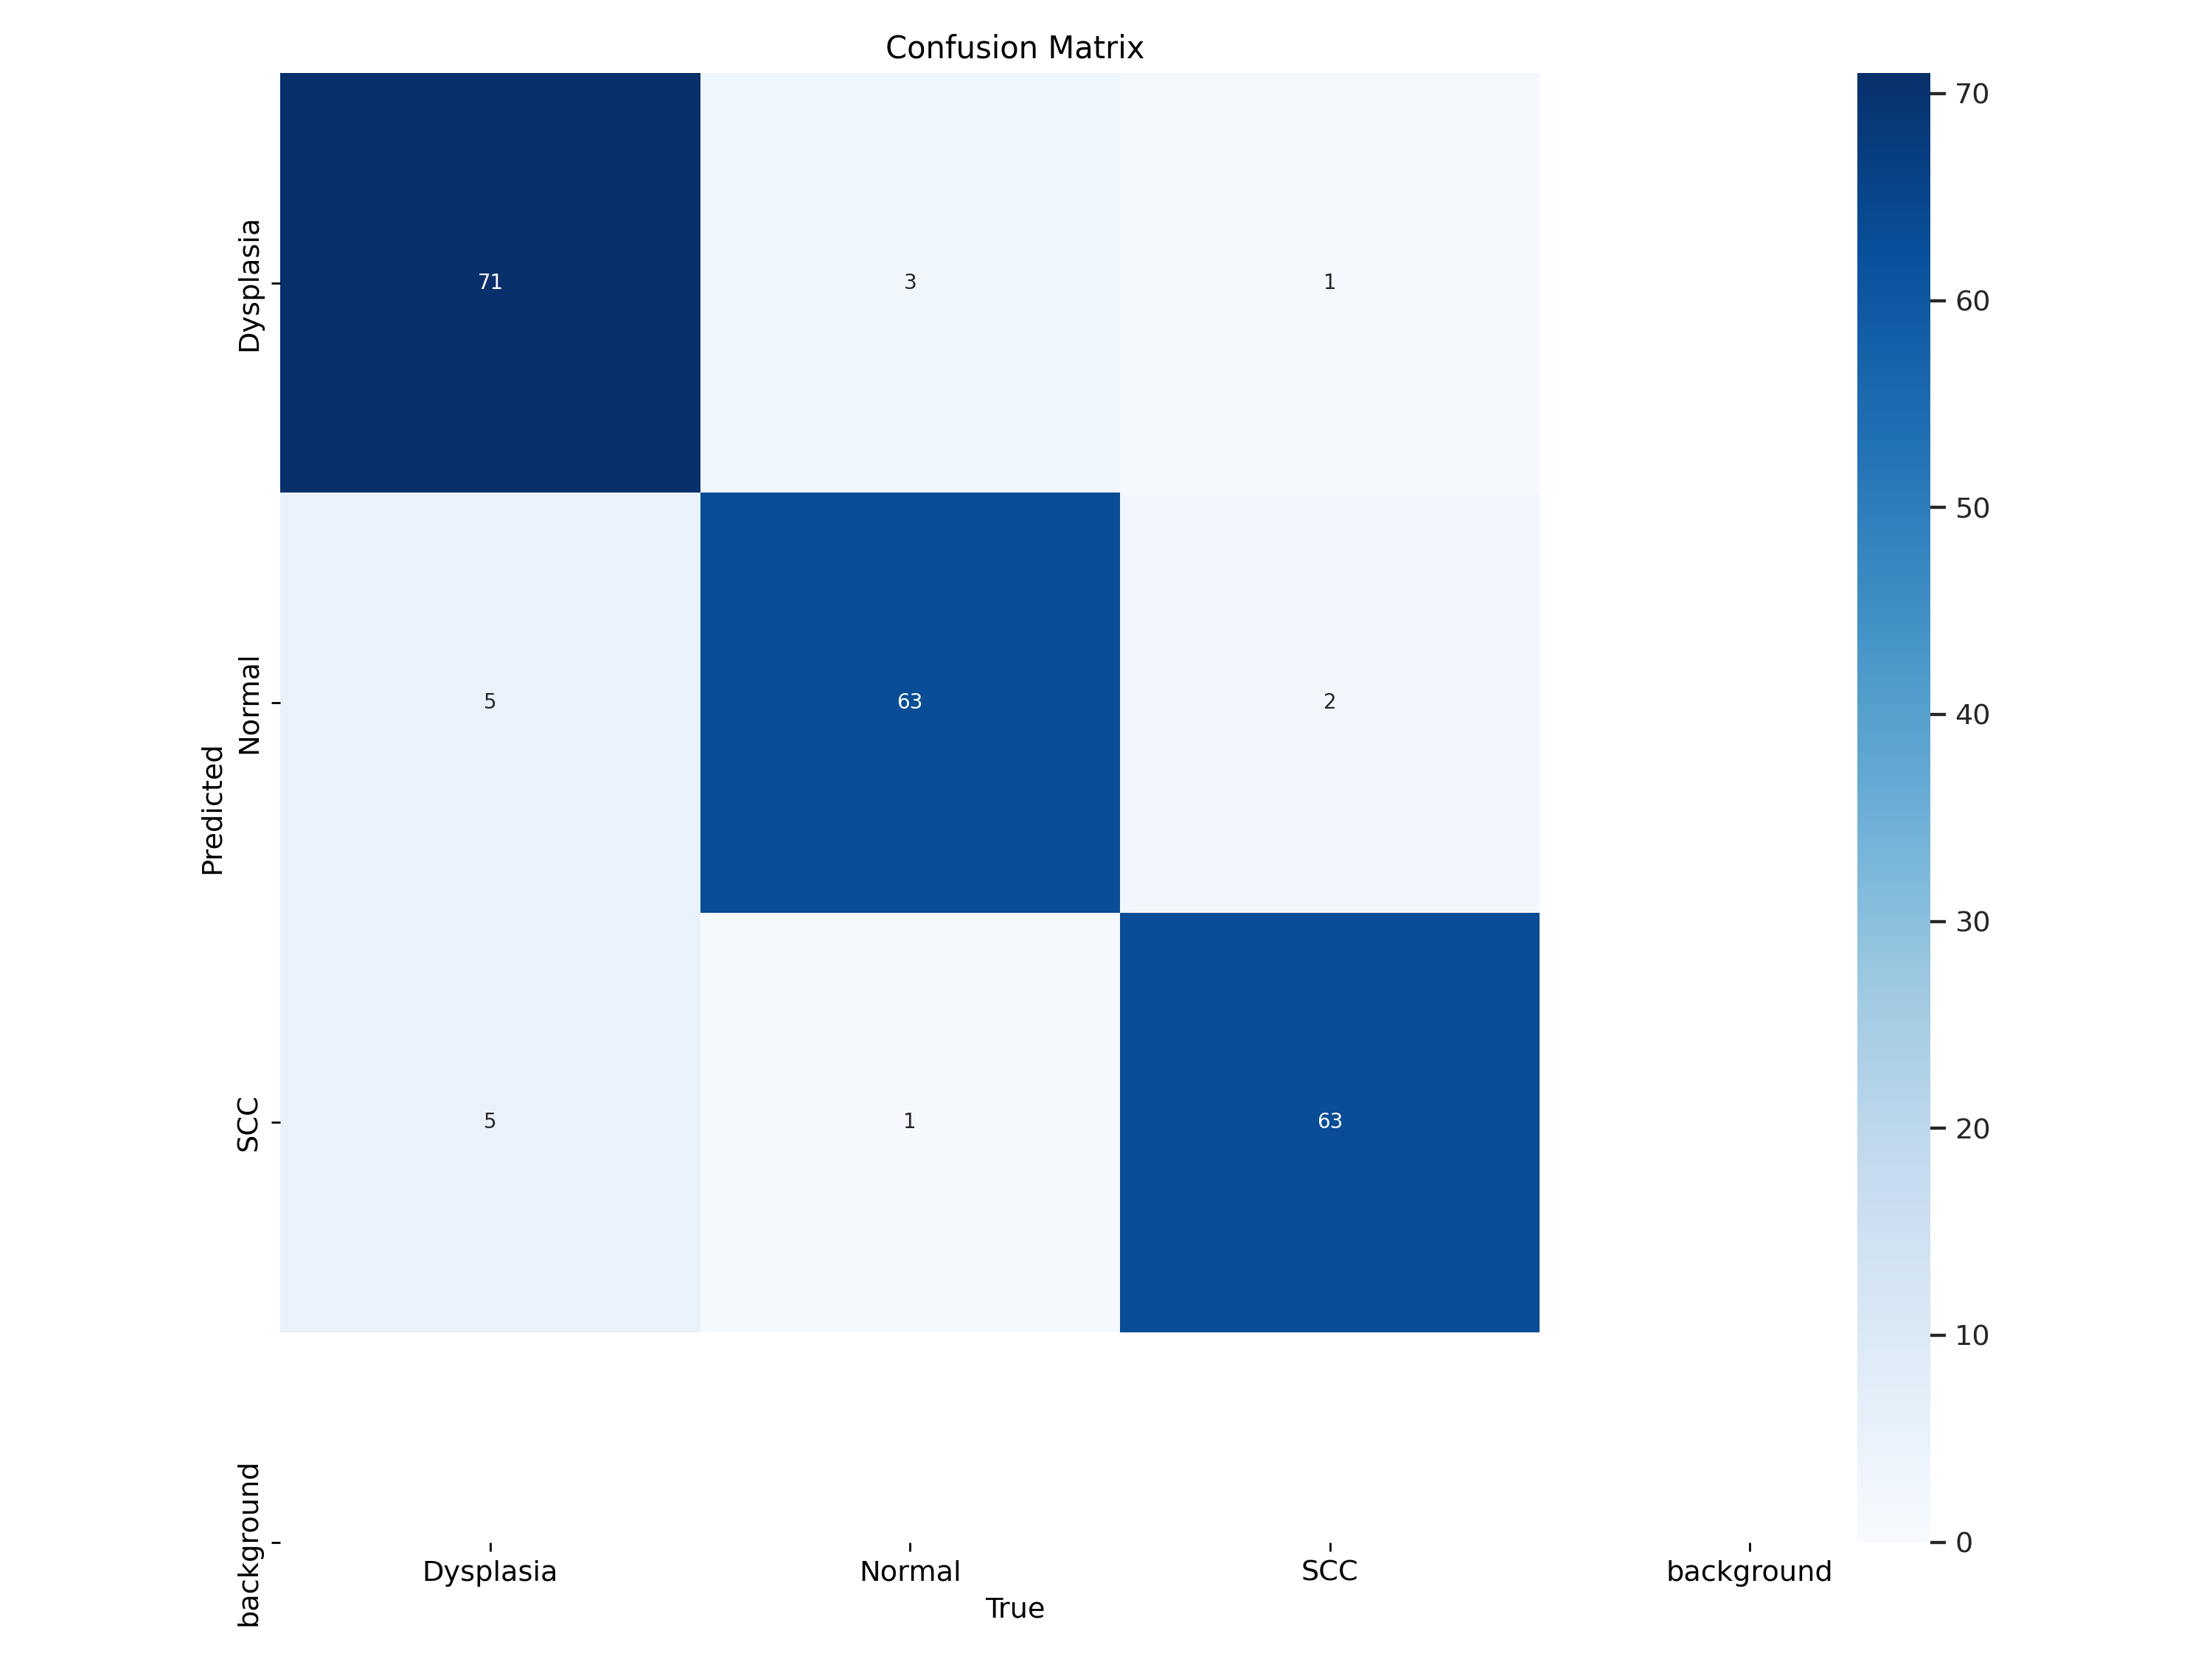

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8x-cls_300_epochs/confusion_matrix.png', width=1000, height=800)

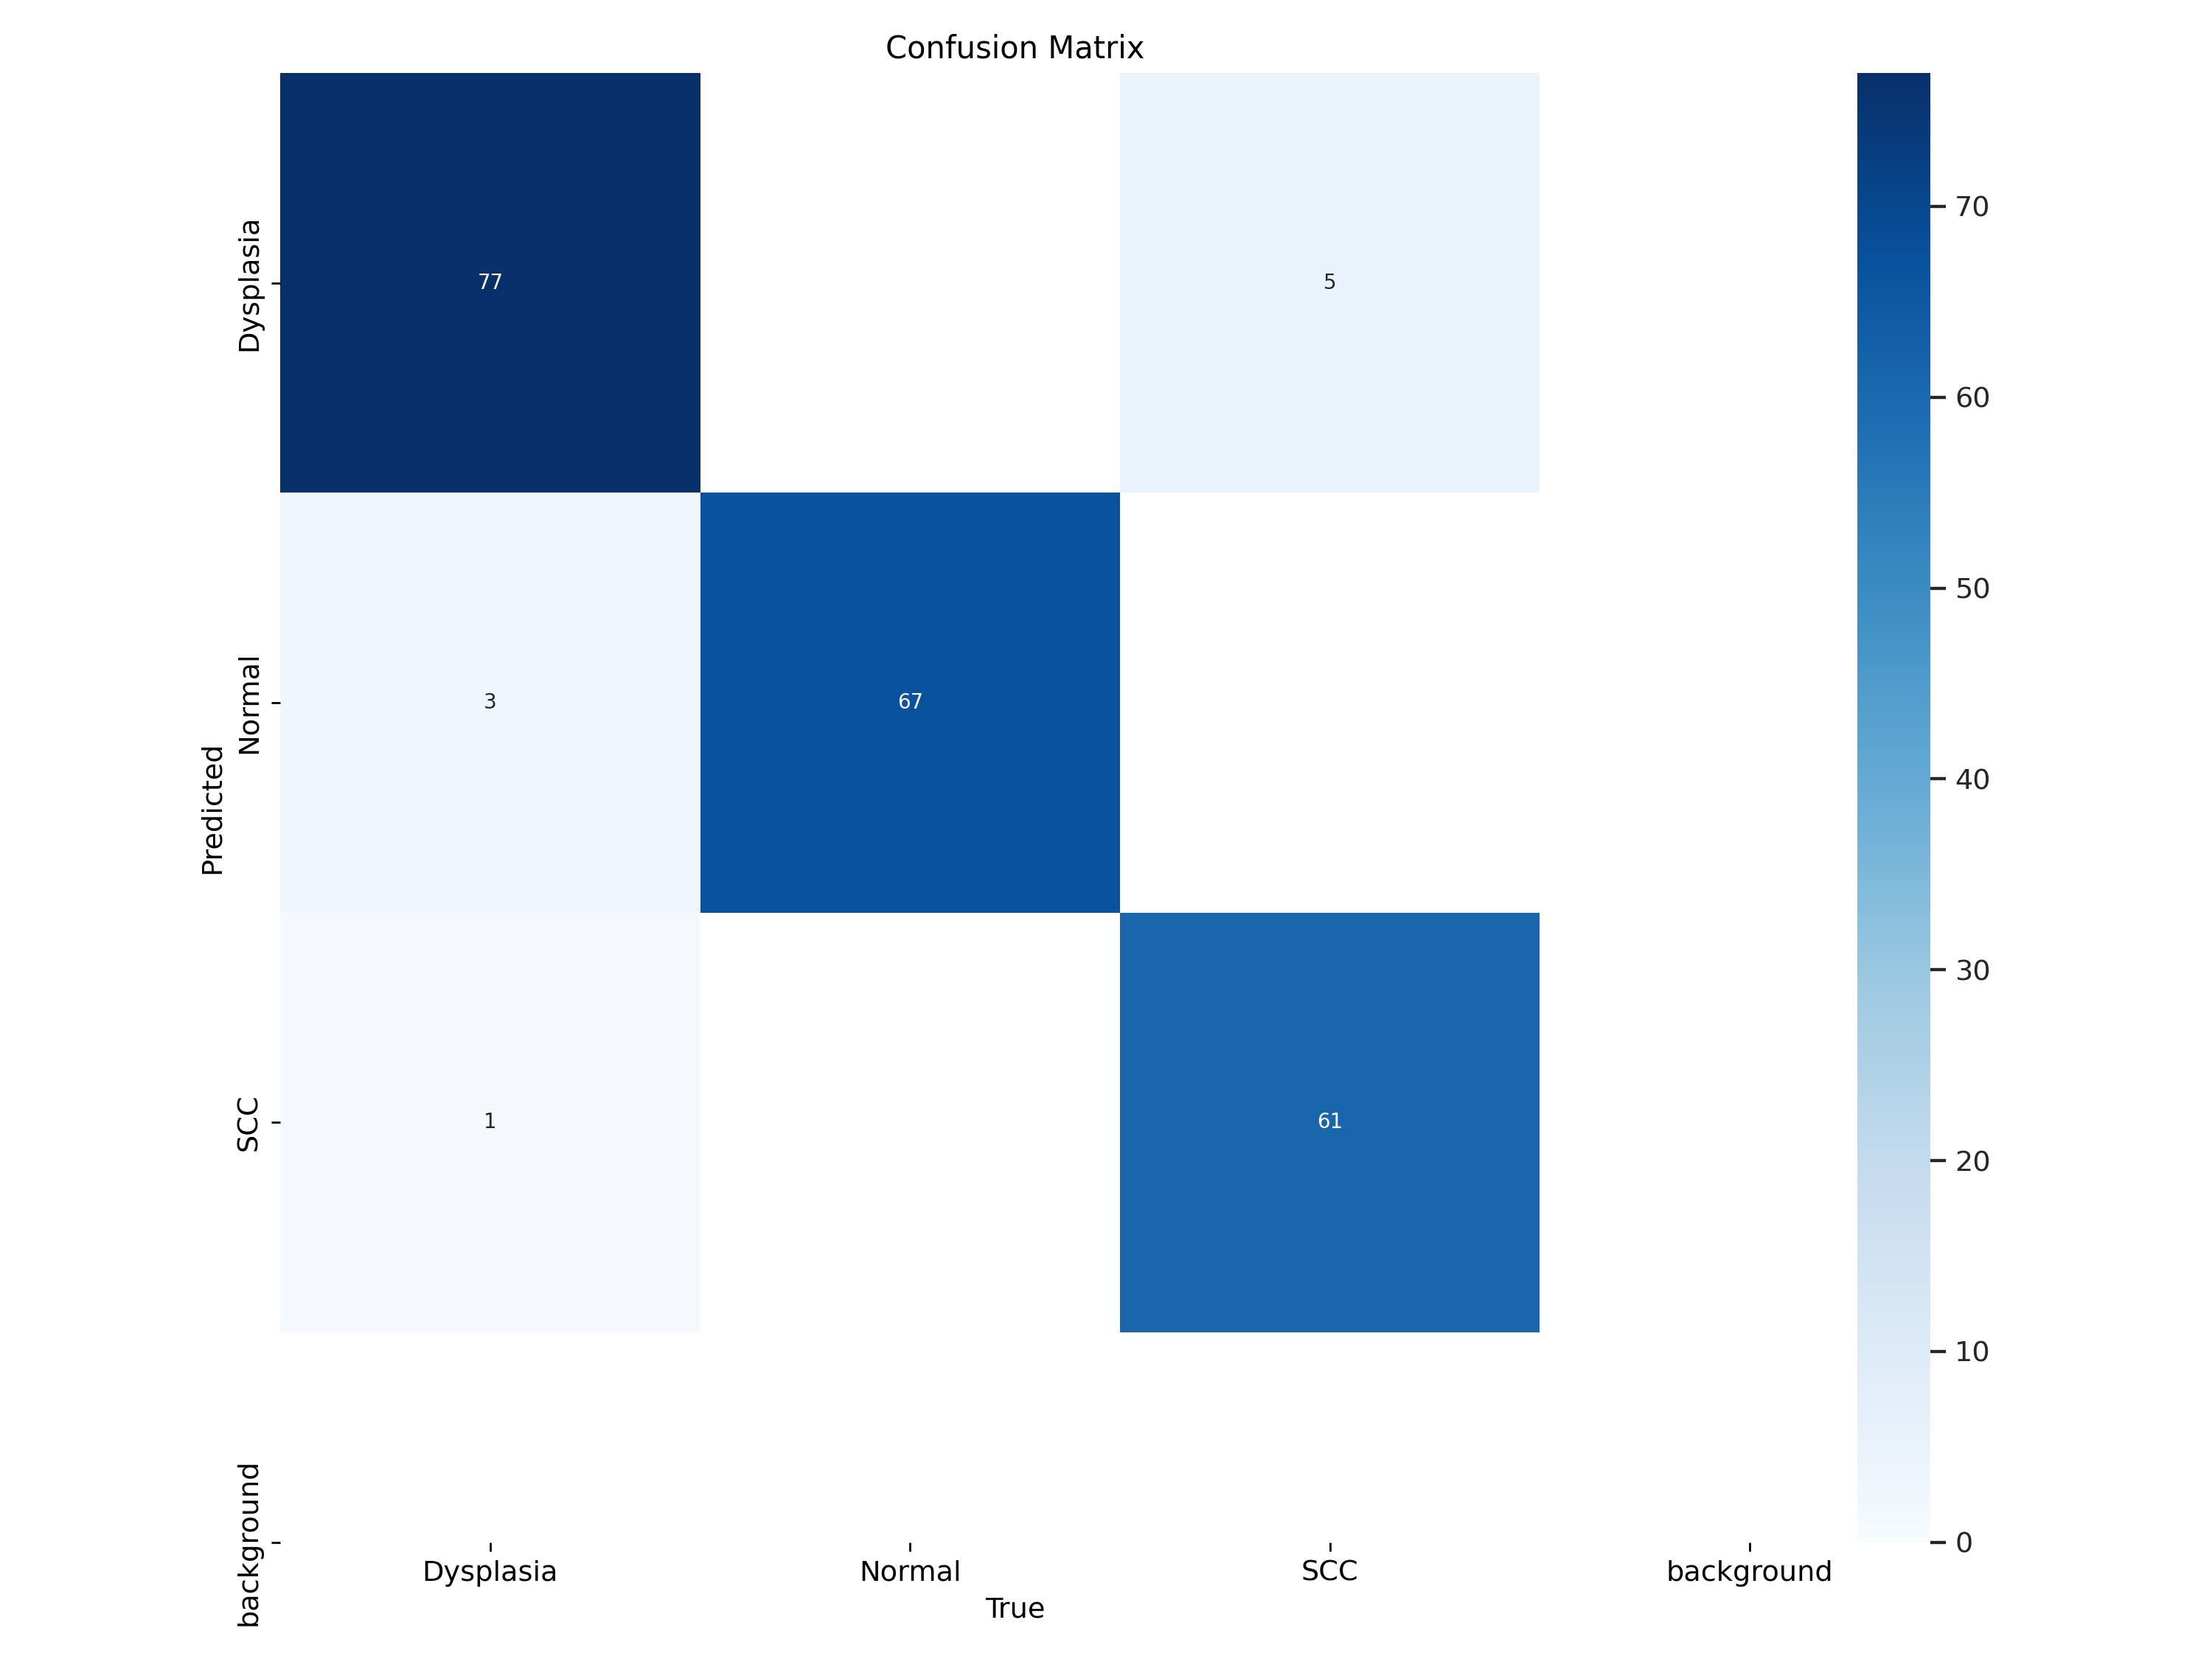

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8n-cls_300_epochs/confusion_matrix.png', width=1000, height=800)

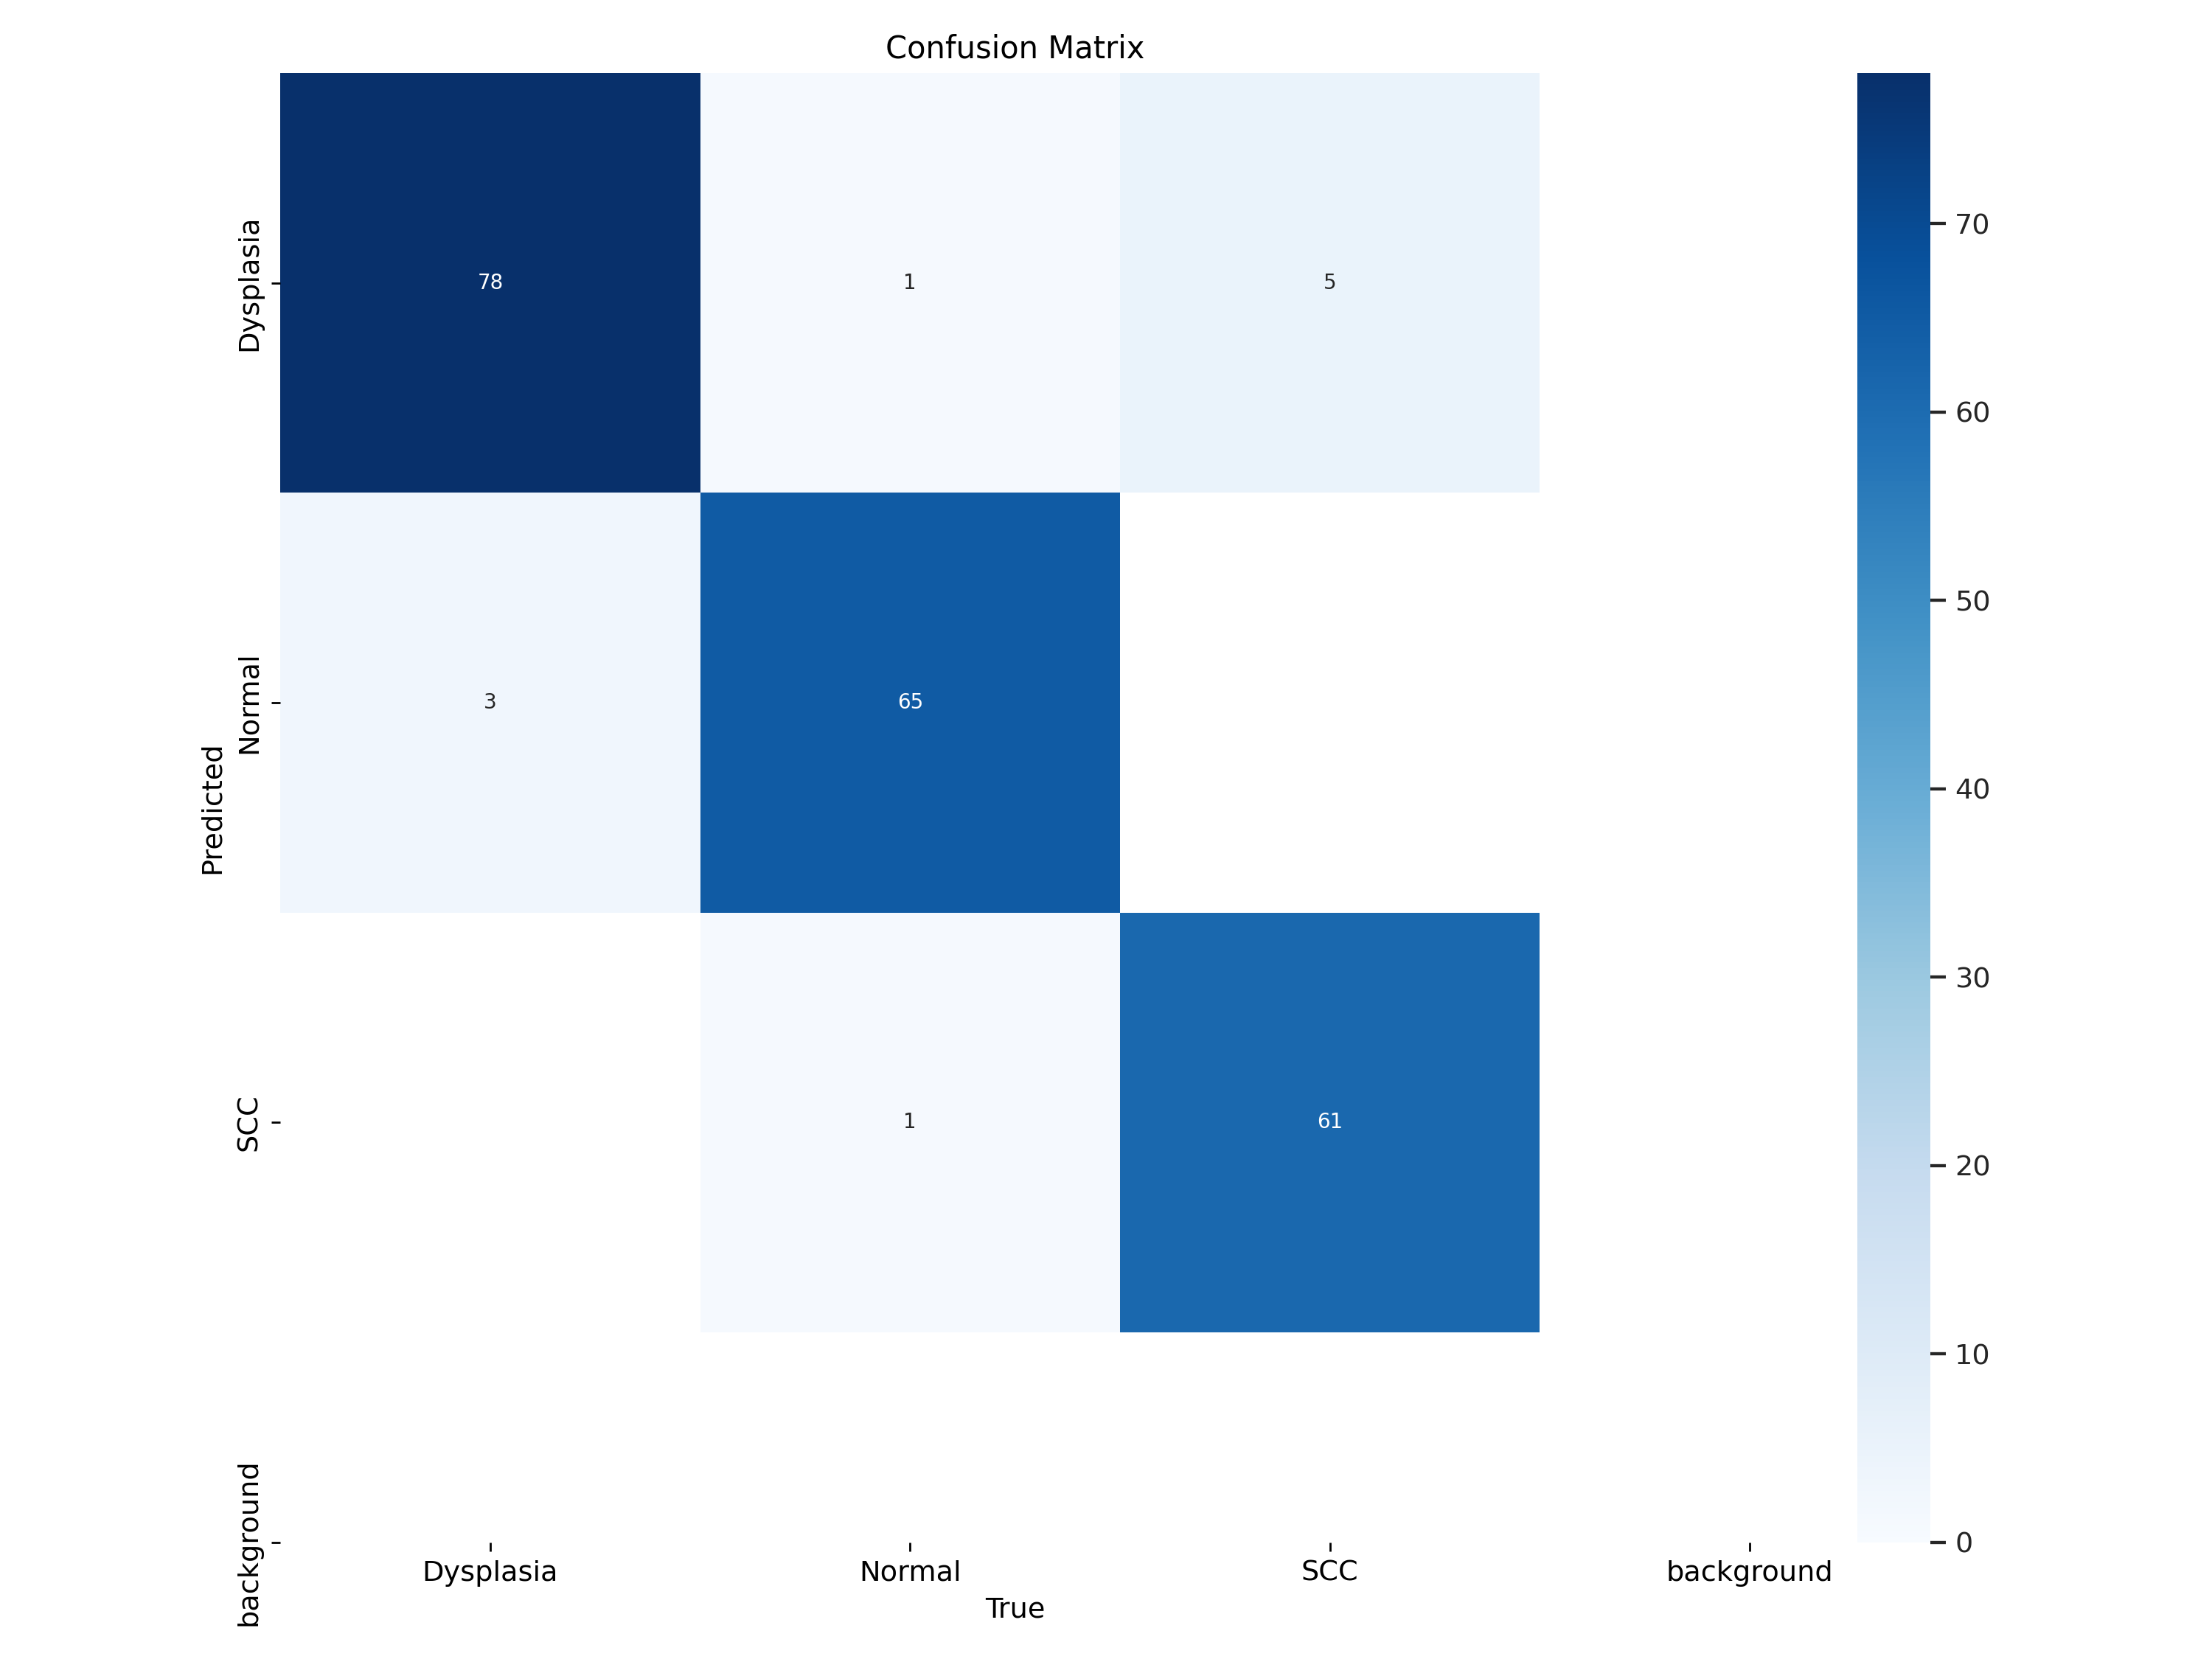

In [ ]:
Image(filename='/content/drive/MyDrive/EC/WLI_split/runs/classify/train2/confusion_matrix.png', width=1000, height=800)

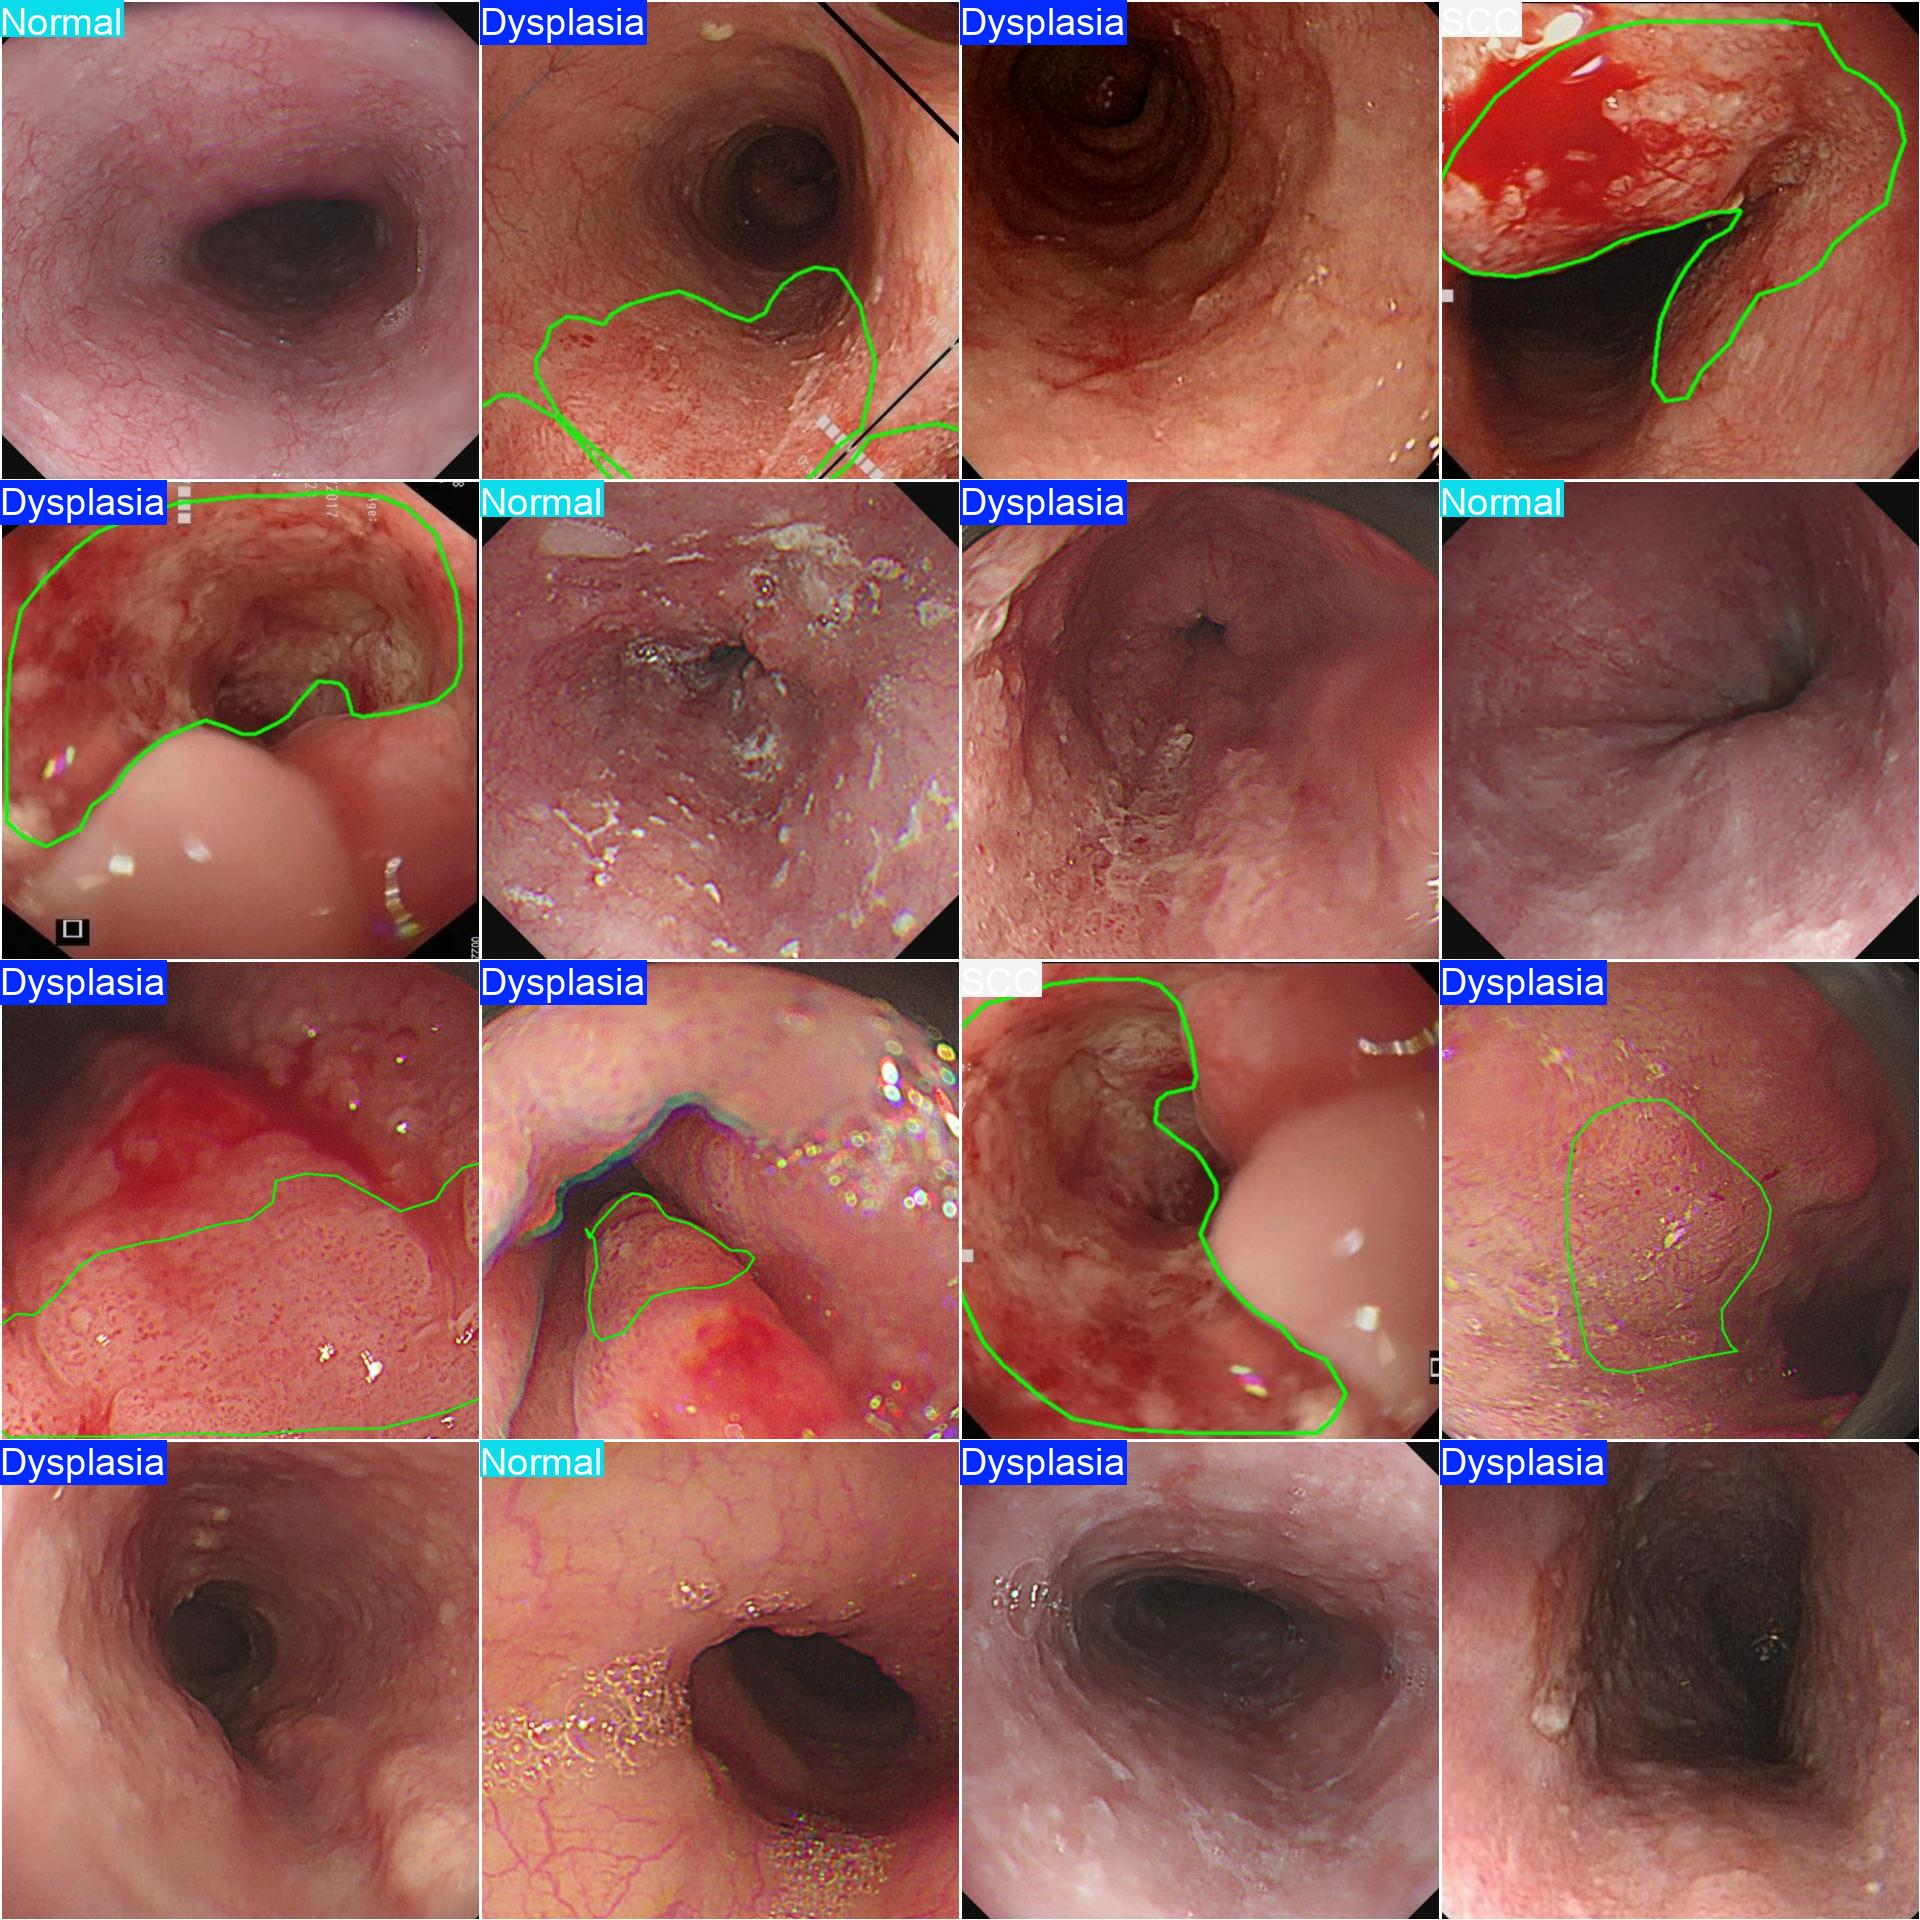

In [ ]:
Image(filename='/content/drive/MyDrive/EC/WLI_split/runs/classify/train2/val_batch2_pred.jpg', width=1000, height=800)




---



---



---



<font color='yellow' size='6'>Test Accuracy of 300th epochs </font>

**best.pt for the 300th epochs of YOLOv8x for the test images**

In [ ]:
from ultralytics import YOLO

# Load the best model
model_x = YOLO('/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8x-cls_300_epochs/weights/best.pt')

# Evaluate on the test dataset
results_x = model_x.val(data='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/', split='test')



Ultralytics YOLOv8.2.79 🚀 Python-3.10.12 torch-2.3.1+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8x-cls summary (fused): 133 layers, 56,127,043 parameters, 0 gradients, 153.8 GFLOPs
train: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/train... found 456 images in 3 classes ✅ 
val: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... found 214 images in 3 classes ✅ 
test: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... found 109 images in 3 classes ✅ 


test: Scanning /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... 109 images, 0 corrupt: 100%|██████████| 109/109 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc: 100%|██████████| 7/7 [06:27<00:00, 55.32s/it]


                   all      0.899          1
Speed: 0.0ms preprocess, 3123.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val3


**best.pt for the 300th epochs of YOLOv8n for the test images**

In [ ]:
from ultralytics import YOLO

# Load the best model
model_n = YOLO('/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt')

# Evaluate on the test dataset
results_n = model_n.val(data='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/', split='test')



Ultralytics YOLOv8.2.79 🚀 Python-3.10.12 torch-2.3.1+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8n-cls summary (fused): 73 layers, 1,438,723 parameters, 0 gradients, 3.3 GFLOPs
train: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/train... found 456 images in 3 classes ✅ 
val: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/val... found 214 images in 3 classes ✅ 
test: /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... found 109 images in 3 classes ✅ 


test: Scanning /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test... 109 images, 0 corrupt: 100%|██████████| 109/109 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc:  14%|█▍        | 1/7 [00:08<00:48,  8.04s/it]


100%|██████████| 755k/755k [00:00<00:00, 12.0MB/s]
               classes   top1_acc   top5_acc: 100%|██████████| 7/7 [00:56<00:00,  8.01s/it]


                   all      0.899          1
Speed: 0.0ms preprocess, 148.7ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val


**Confusion Matrics for test images**

**YOLOv8n**

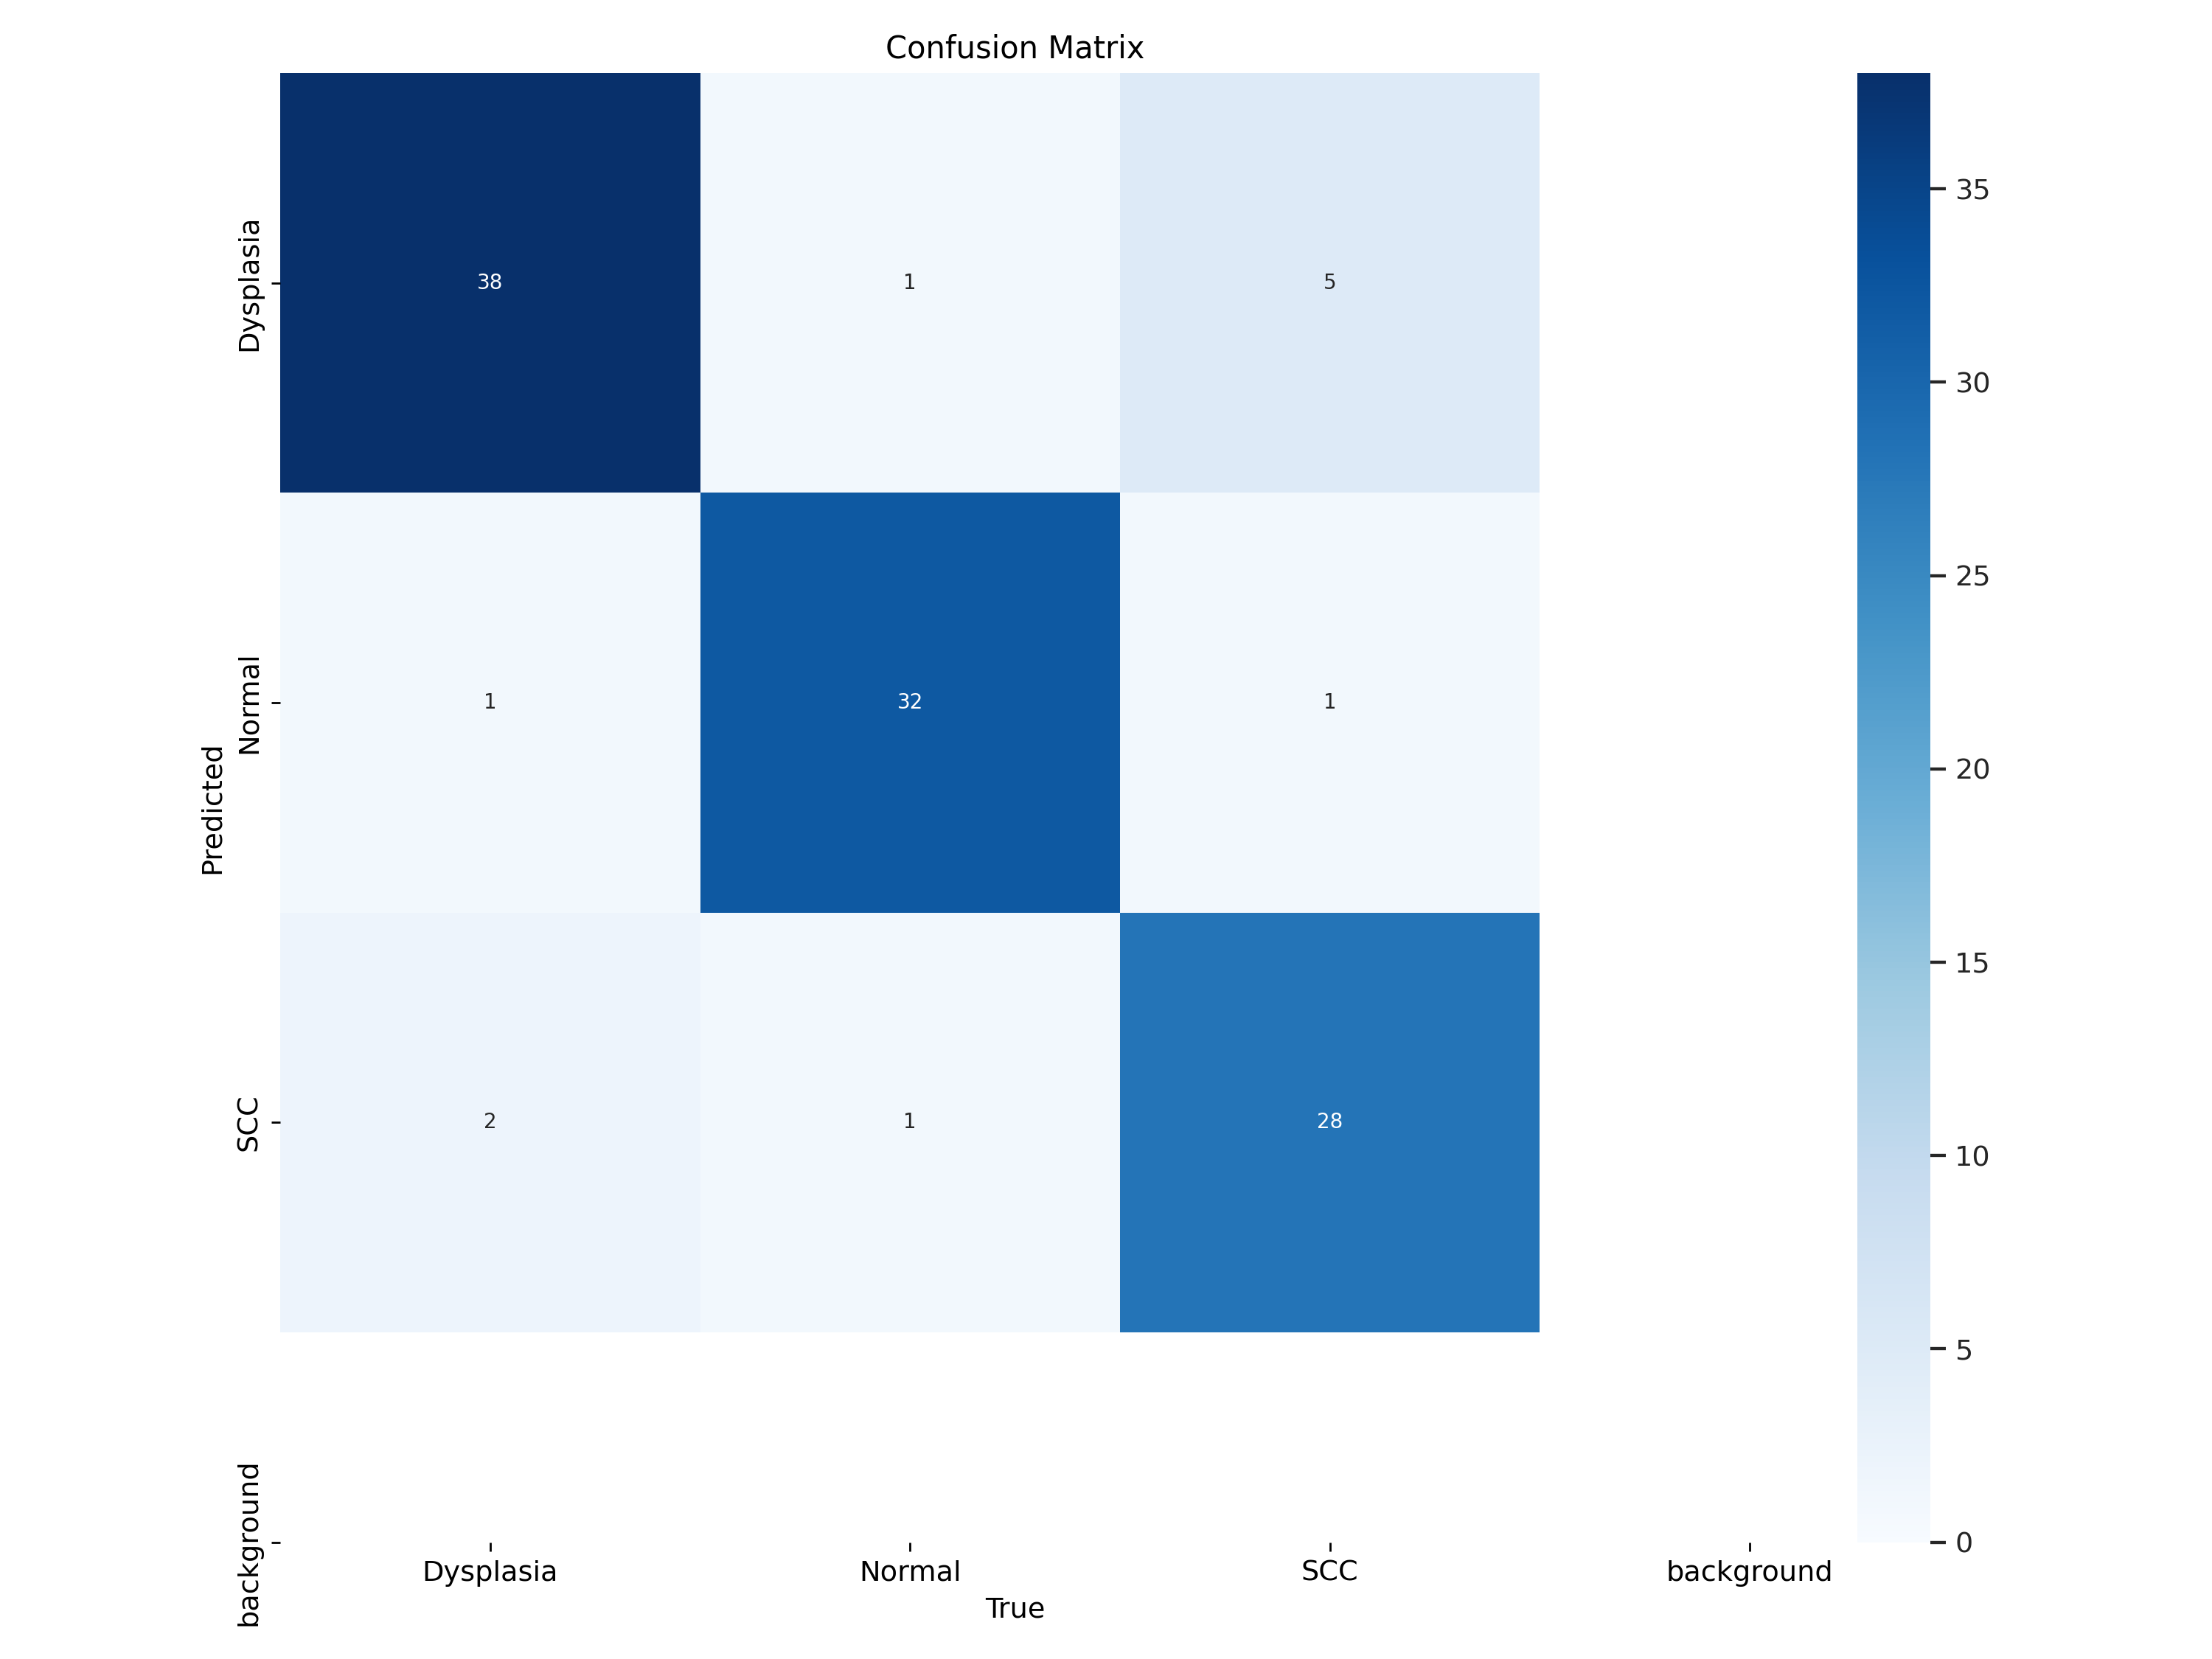

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test_runs/300_test_n/confusion_matrix.png', width=1000, height=700)


**YOLOv8n classification report**

In [ ]:
from sklearn.metrics import classification_report
confusion_matrix_n = [
    [38, 1, 5],  # Dysplasia
    [1, 32, 1],  # Normal
    [2, 1, 28]   # SCC
]

# Assuming your class names are in this order
class_names = ["Dysplasia", "Normal", "SCC"]

# Derive y_true and y_pred from the confusion matrix
y_true = []
y_pred = []
for i in range(len(confusion_matrix_n)):
    for j in range(len(confusion_matrix_n[i])):
        y_true.extend([class_names[i]] * confusion_matrix_n[i][j])
        y_pred.extend([class_names[j]] * confusion_matrix_n[i][j])

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)


              precision    recall  f1-score   support

   Dysplasia       0.93      0.86      0.89        44
      Normal       0.94      0.94      0.94        34
         SCC       0.82      0.90      0.86        31

    accuracy                           0.90       109
   macro avg       0.90      0.90      0.90       109
weighted avg       0.90      0.90      0.90       109



**YOLOv8x**

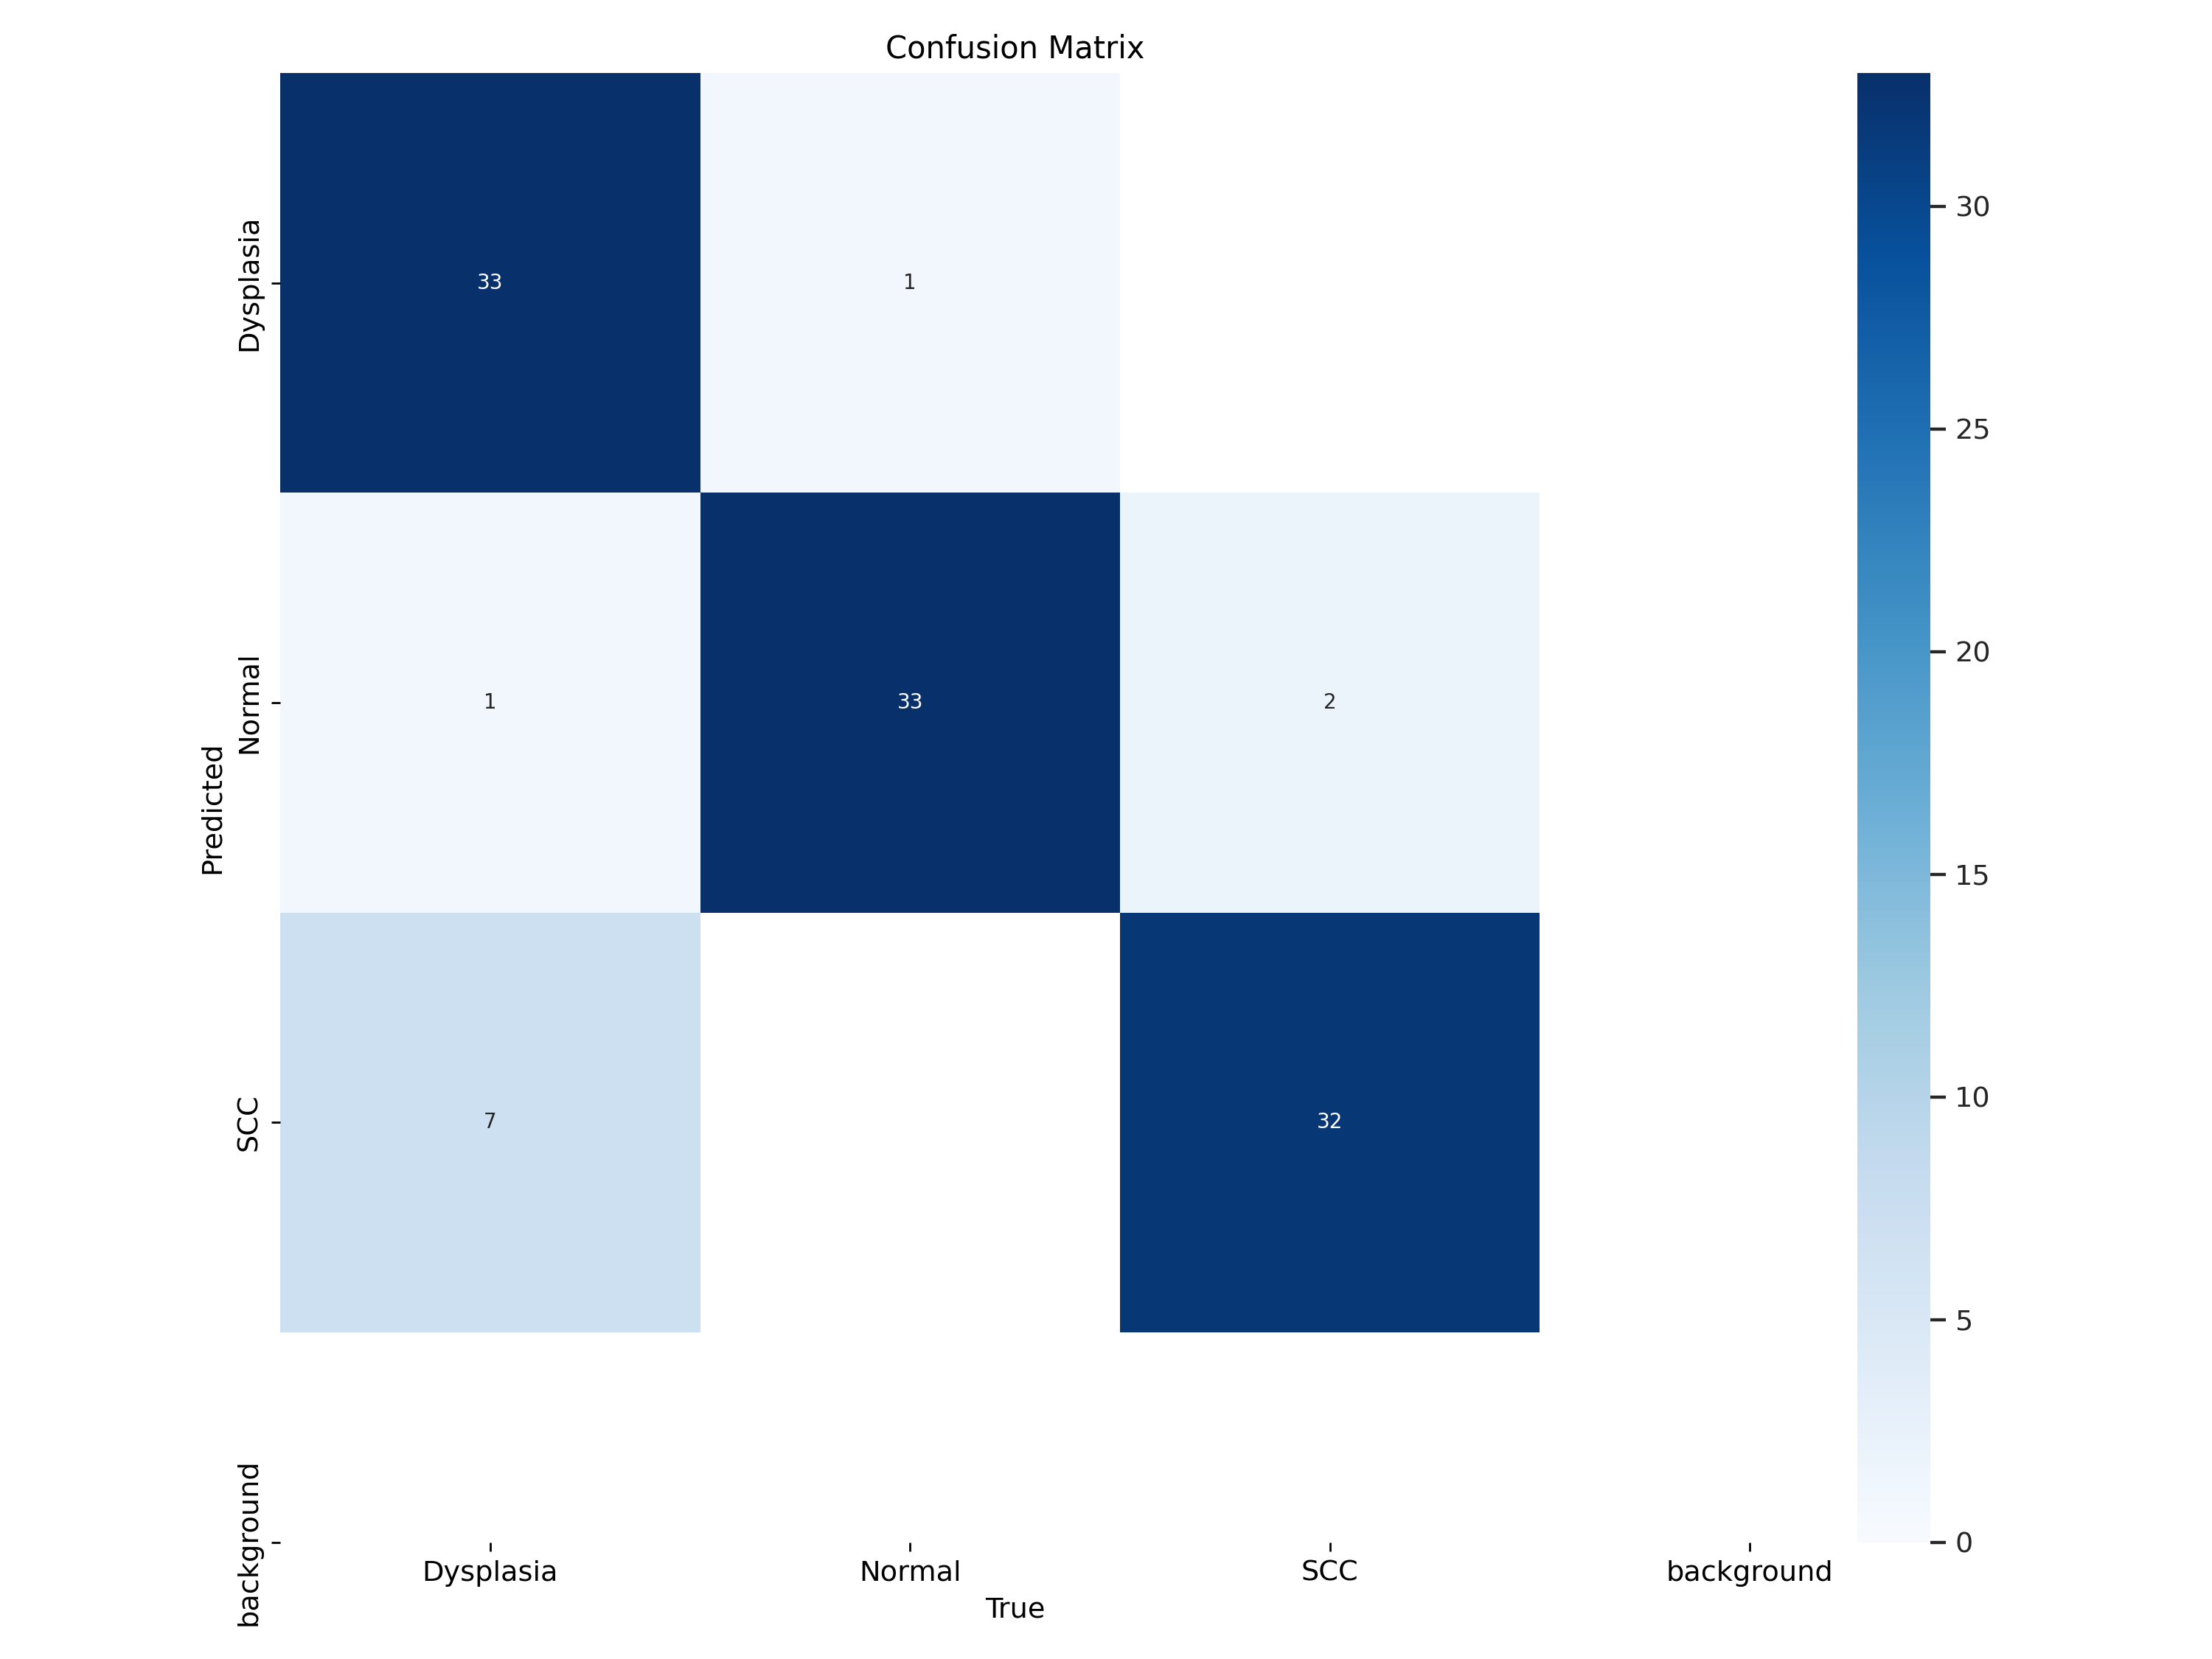

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test_runs/300_test_x/confusion_matrix.png', width=1000, height=700)


**YOLOv8x classification report**

In [ ]:
from sklearn.metrics import classification_report
confusion_matrix_x = [
    [33, 1, 0],  # Dysplasia
    [1, 33, 2],  # Normal
    [7, 0, 32]   # SCC
]

# Assuming your class names are in this order
class_names = ["Dysplasia", "Normal", "SCC"]

# Derive y_true and y_pred from the confusion matrix
y_true_x = []
y_pred_x = []
for m in range(len(confusion_matrix_x)):
    for k in range(len(confusion_matrix_x[m])):
        y_true_x.extend([class_names[m]] * confusion_matrix_x[m][k])
        y_pred_x.extend([class_names[k]] * confusion_matrix_x[m][k])

report_x = classification_report(y_true_x, y_pred_x, target_names=class_names)
print(report_x)


              precision    recall  f1-score   support

   Dysplasia       0.80      0.97      0.88        34
      Normal       0.97      0.92      0.94        36
         SCC       0.94      0.82      0.88        39

    accuracy                           0.90       109
   macro avg       0.91      0.90      0.90       109
weighted avg       0.91      0.90      0.90       109



<font color='yellow' size='3'>After comparing the best results of YOLOv8n and YOLOv8x at their 300th epochs, i found out that YOLOv8n is performing better  so the further prediction of images will be done with that.</font><br>

In [ ]:
from ultralytics import YOLO

import numpy as np


model = YOLO('/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt')  # load a custom model

results = model('/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/001_REC20200907-130116613_ 0214.jpg')  # predict on an image

names_dict = results[0].names

probs = results[0].probs.data.tolist()

print(names_dict)
print(probs)

print(names_dict[np.argmax(probs)])


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/001_REC20200907-130116613_ 0214.jpg: 640x640 SCC 0.98, Dysplasia 0.02, Normal 0.00, 90.3ms
Speed: 21.4ms preprocess, 90.3ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)
{0: 'Dysplasia', 1: 'Normal', 2: 'SCC'}
[0.01837850920855999, 1.29338668557466e-05, 0.9816085696220398]
SCC



image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/REC20200907-130116613__000406_jpg.rf.f537b0918a8fd327e7e6d5f5a0f9bd4d.jpg: 640x640 SCC 1.00, Dysplasia 0.00, Normal 0.00, 365.7ms
Speed: 141.5ms preprocess, 365.7ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 640)


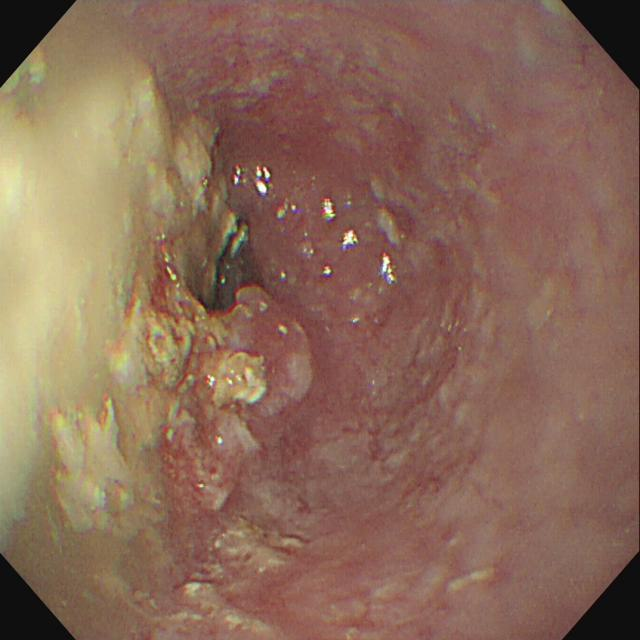


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/CA073.jpg: 640x640 SCC 1.00, Dysplasia 0.00, Normal 0.00, 336.0ms
Speed: 48.9ms preprocess, 336.0ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


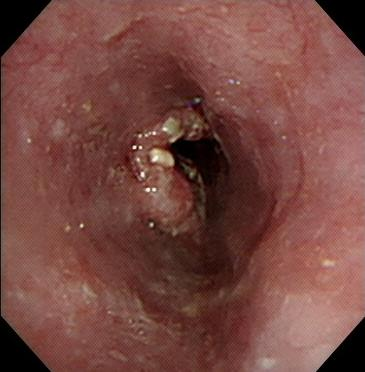


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/REC20200907-130116613__000421_jpg.rf.226c531d440d4cbadd63e39052a3237b.jpg: 640x640 SCC 1.00, Dysplasia 0.00, Normal 0.00, 268.5ms
Speed: 25.2ms preprocess, 268.5ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


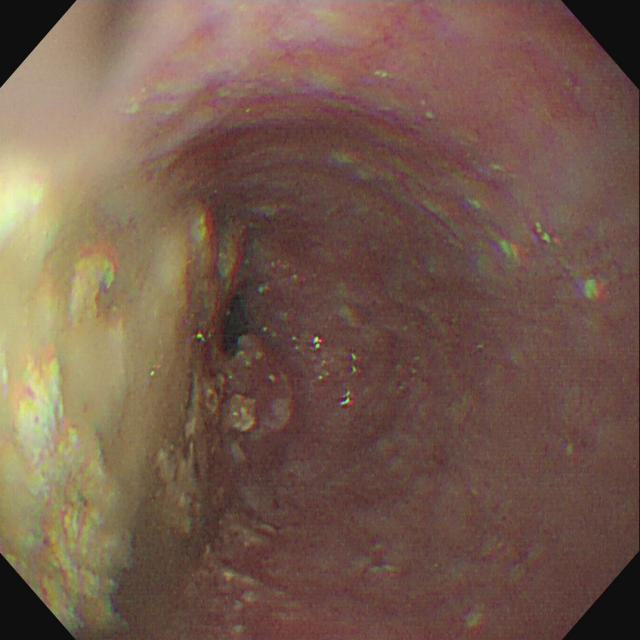


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/SCC/augmented_11_REC20200904-133725241_ 1048.jpg: 640x640 Dysplasia 0.97, SCC 0.03, Normal 0.00, 366.9ms
Speed: 33.5ms preprocess, 366.9ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


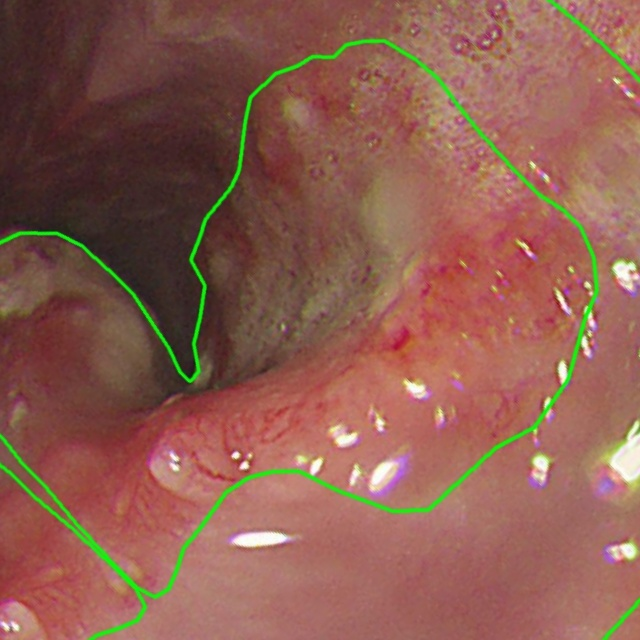


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Normal/augmented_0009123533-LVL B_No dysplasia_frame000002_90.jpg: 640x640 Normal 1.00, SCC 0.00, Dysplasia 0.00, 331.3ms
Speed: 20.4ms preprocess, 331.3ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


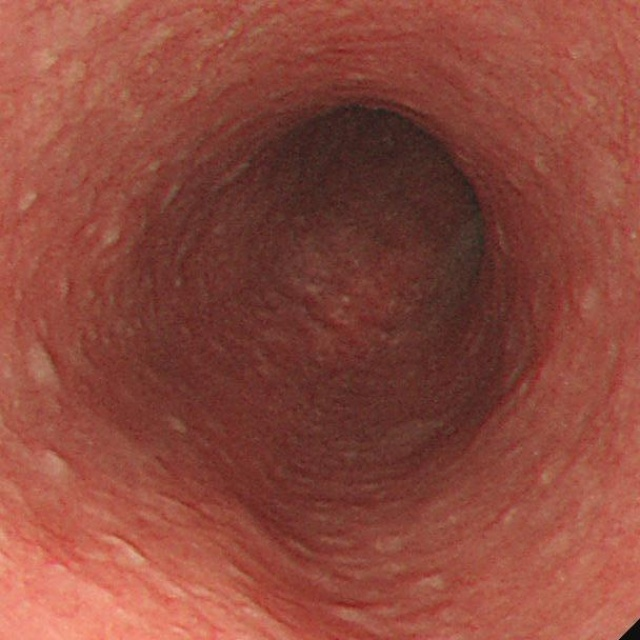


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Normal/img091.jpg: 640x640 Normal 1.00, Dysplasia 0.00, SCC 0.00, 351.6ms
Speed: 60.6ms preprocess, 351.6ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


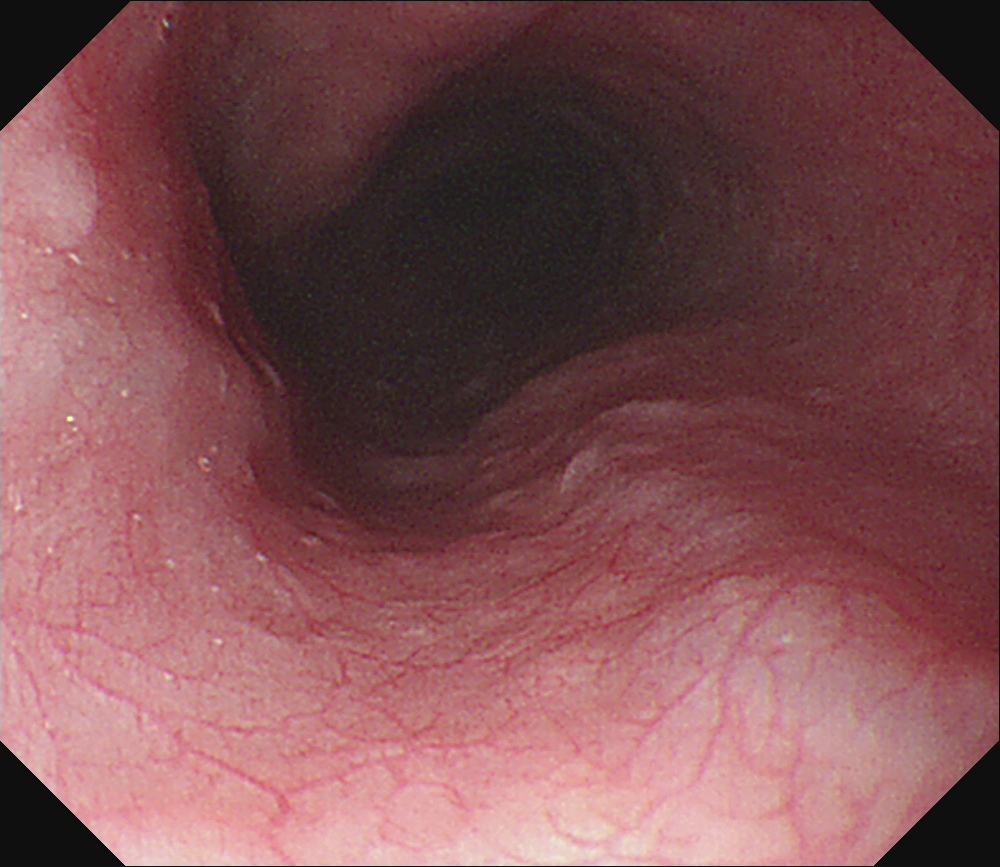


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Normal/08888710 (2).jpg: 640x640 Normal 1.00, Dysplasia 0.00, SCC 0.00, 393.0ms
Speed: 72.2ms preprocess, 393.0ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


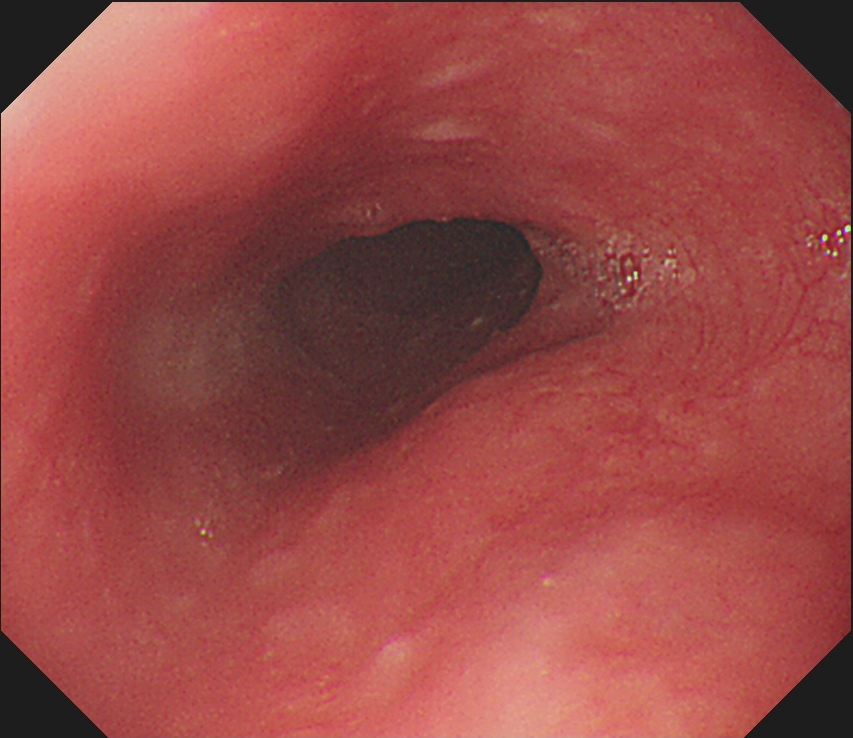


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Normal/09132978_20141226_WL.jpg: 640x640 Normal 0.91, Dysplasia 0.09, SCC 0.00, 481.1ms
Speed: 45.6ms preprocess, 481.1ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


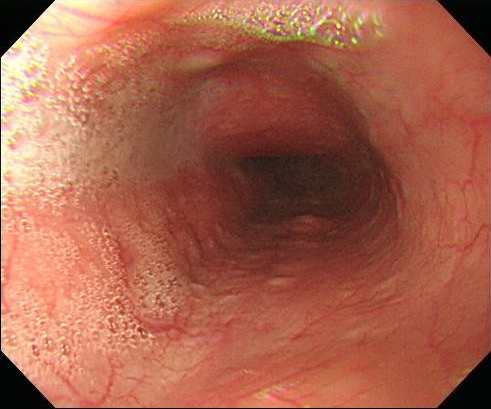


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Dysplasia/img064.jpg: 640x640 Dysplasia 0.99, SCC 0.00, Normal 0.00, 307.0ms
Speed: 35.5ms preprocess, 307.0ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


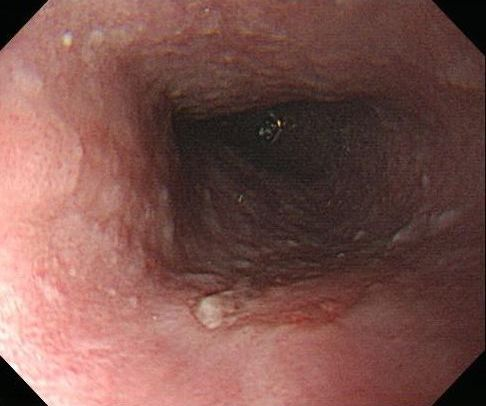


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Dysplasia/img149.jpg: 640x640 Dysplasia 0.96, Normal 0.04, SCC 0.00, 314.4ms
Speed: 80.3ms preprocess, 314.4ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


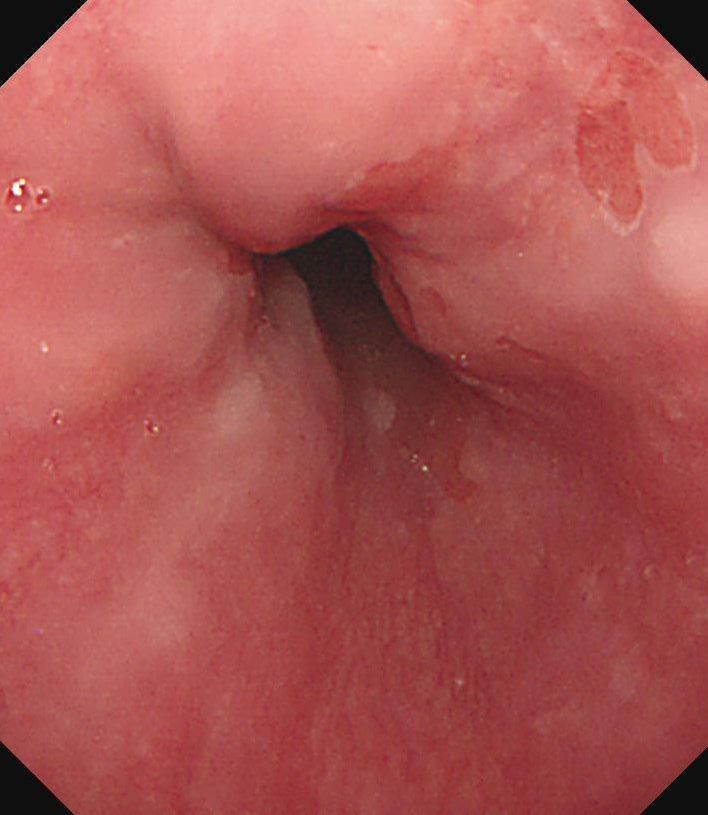


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Dysplasia/FILE28_2.jpg: 640x640 Dysplasia 1.00, Normal 0.00, SCC 0.00, 384.2ms
Speed: 79.1ms preprocess, 384.2ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


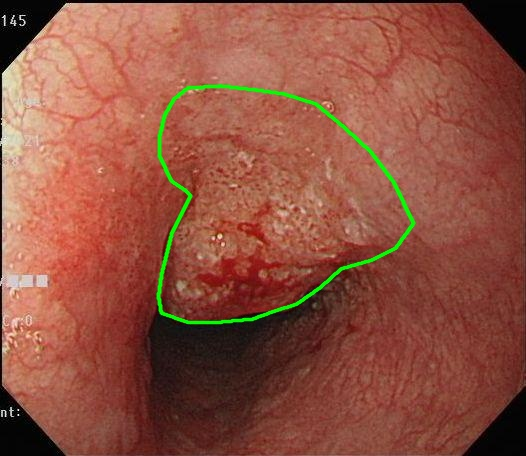


image 1/1 /content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/Dysplasia/111.jpg: 640x640 Dysplasia 1.00, SCC 0.00, Normal 0.00, 146.9ms
Speed: 97.6ms preprocess, 146.9ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


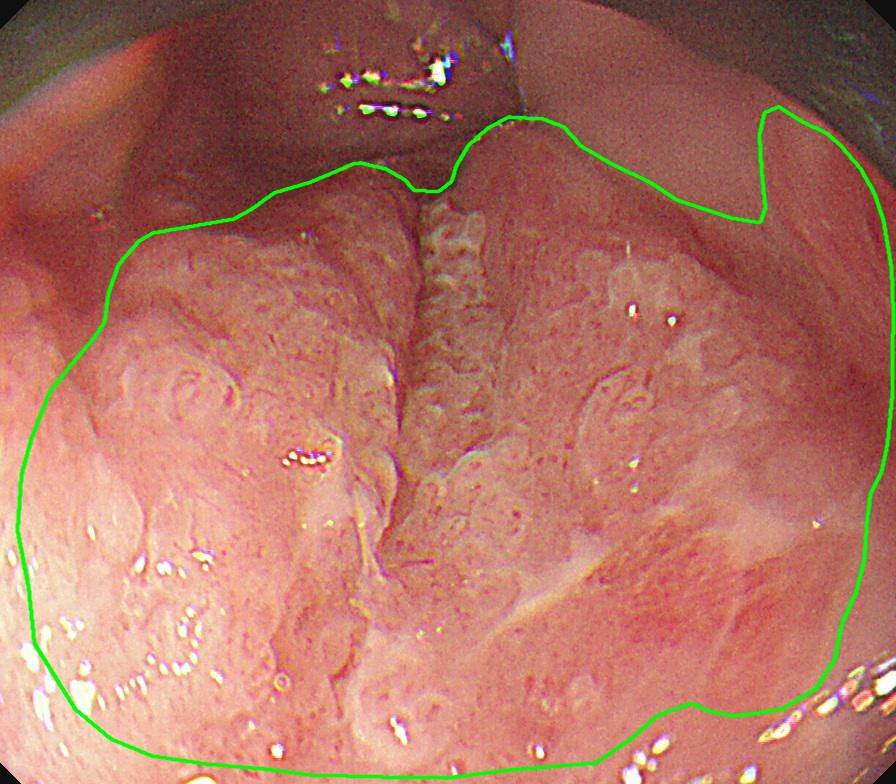

In [ ]:
import os
from IPython.display import Image, display

# Initialize lists to store true and predicted labels
true_labels = []
pred_labels = []
# Path to your saved model
model_path = '/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt'

# Load your saved model
model = YOLO(model_path)

# Path to your test images directory
test_images_dir = '/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test/'

# Define class names (replace with your actual class names)
class_names = ['Dysplasia', 'Normal', 'SCC']

# Function to get true label (replace with your logic to extract true label from filename or other source)
def get_true_label(image_file):
    # Example: Assuming the image filename contains the true label as a prefix
    return image_file.split('_')[0]

# Check if the directory exists
if not os.path.exists(test_images_dir):
    print(f"Test images directory not found: {test_images_dir}")

# Iterate over subdirectories and images
for class_dir in os.listdir(test_images_dir):
    class_path = os.path.join(test_images_dir, class_dir)
    # Check if it is a directory and not a file
    if os.path.isdir(class_path):
        image_count = 0
        for image_file in os.listdir(class_path):
            if image_count >= 4:
                break  # Limit to 4 images per class

            image_path = os.path.join(class_path, image_file)
            if os.path.isfile(image_path):
                try:
                    results = model(image_path) # Use model as a callable for prediction

                    # Display image and prediction results with reduced figure size
                    display(Image(filename=image_path, width=300))  # Adjust width as needed
                    for result in results:
                        boxes = result.boxes  # Access boxes directly
                        if boxes:
                            for r in boxes.data.tolist():
                                conf = r[4]  # Confidence score
                                pred_class = int(r[5])  # Predicted class index
                                pred_label = class_names[pred_class]

                                true_label = get_true_label(image_file)

                                # Store the true and predicted labels
                                true_labels.append(true_label)
                                pred_labels.append(pred_label)

                                print(f"Confidence: {conf:.2f}, Predicted Label: {pred_label}, True Label: {true_label}")


                    image_count += 1
                except Exception as e:
                    print(f"Error processing {image_path}: {e}")
    else:
        print(f"Skipping non-directory entry: {class_path}")


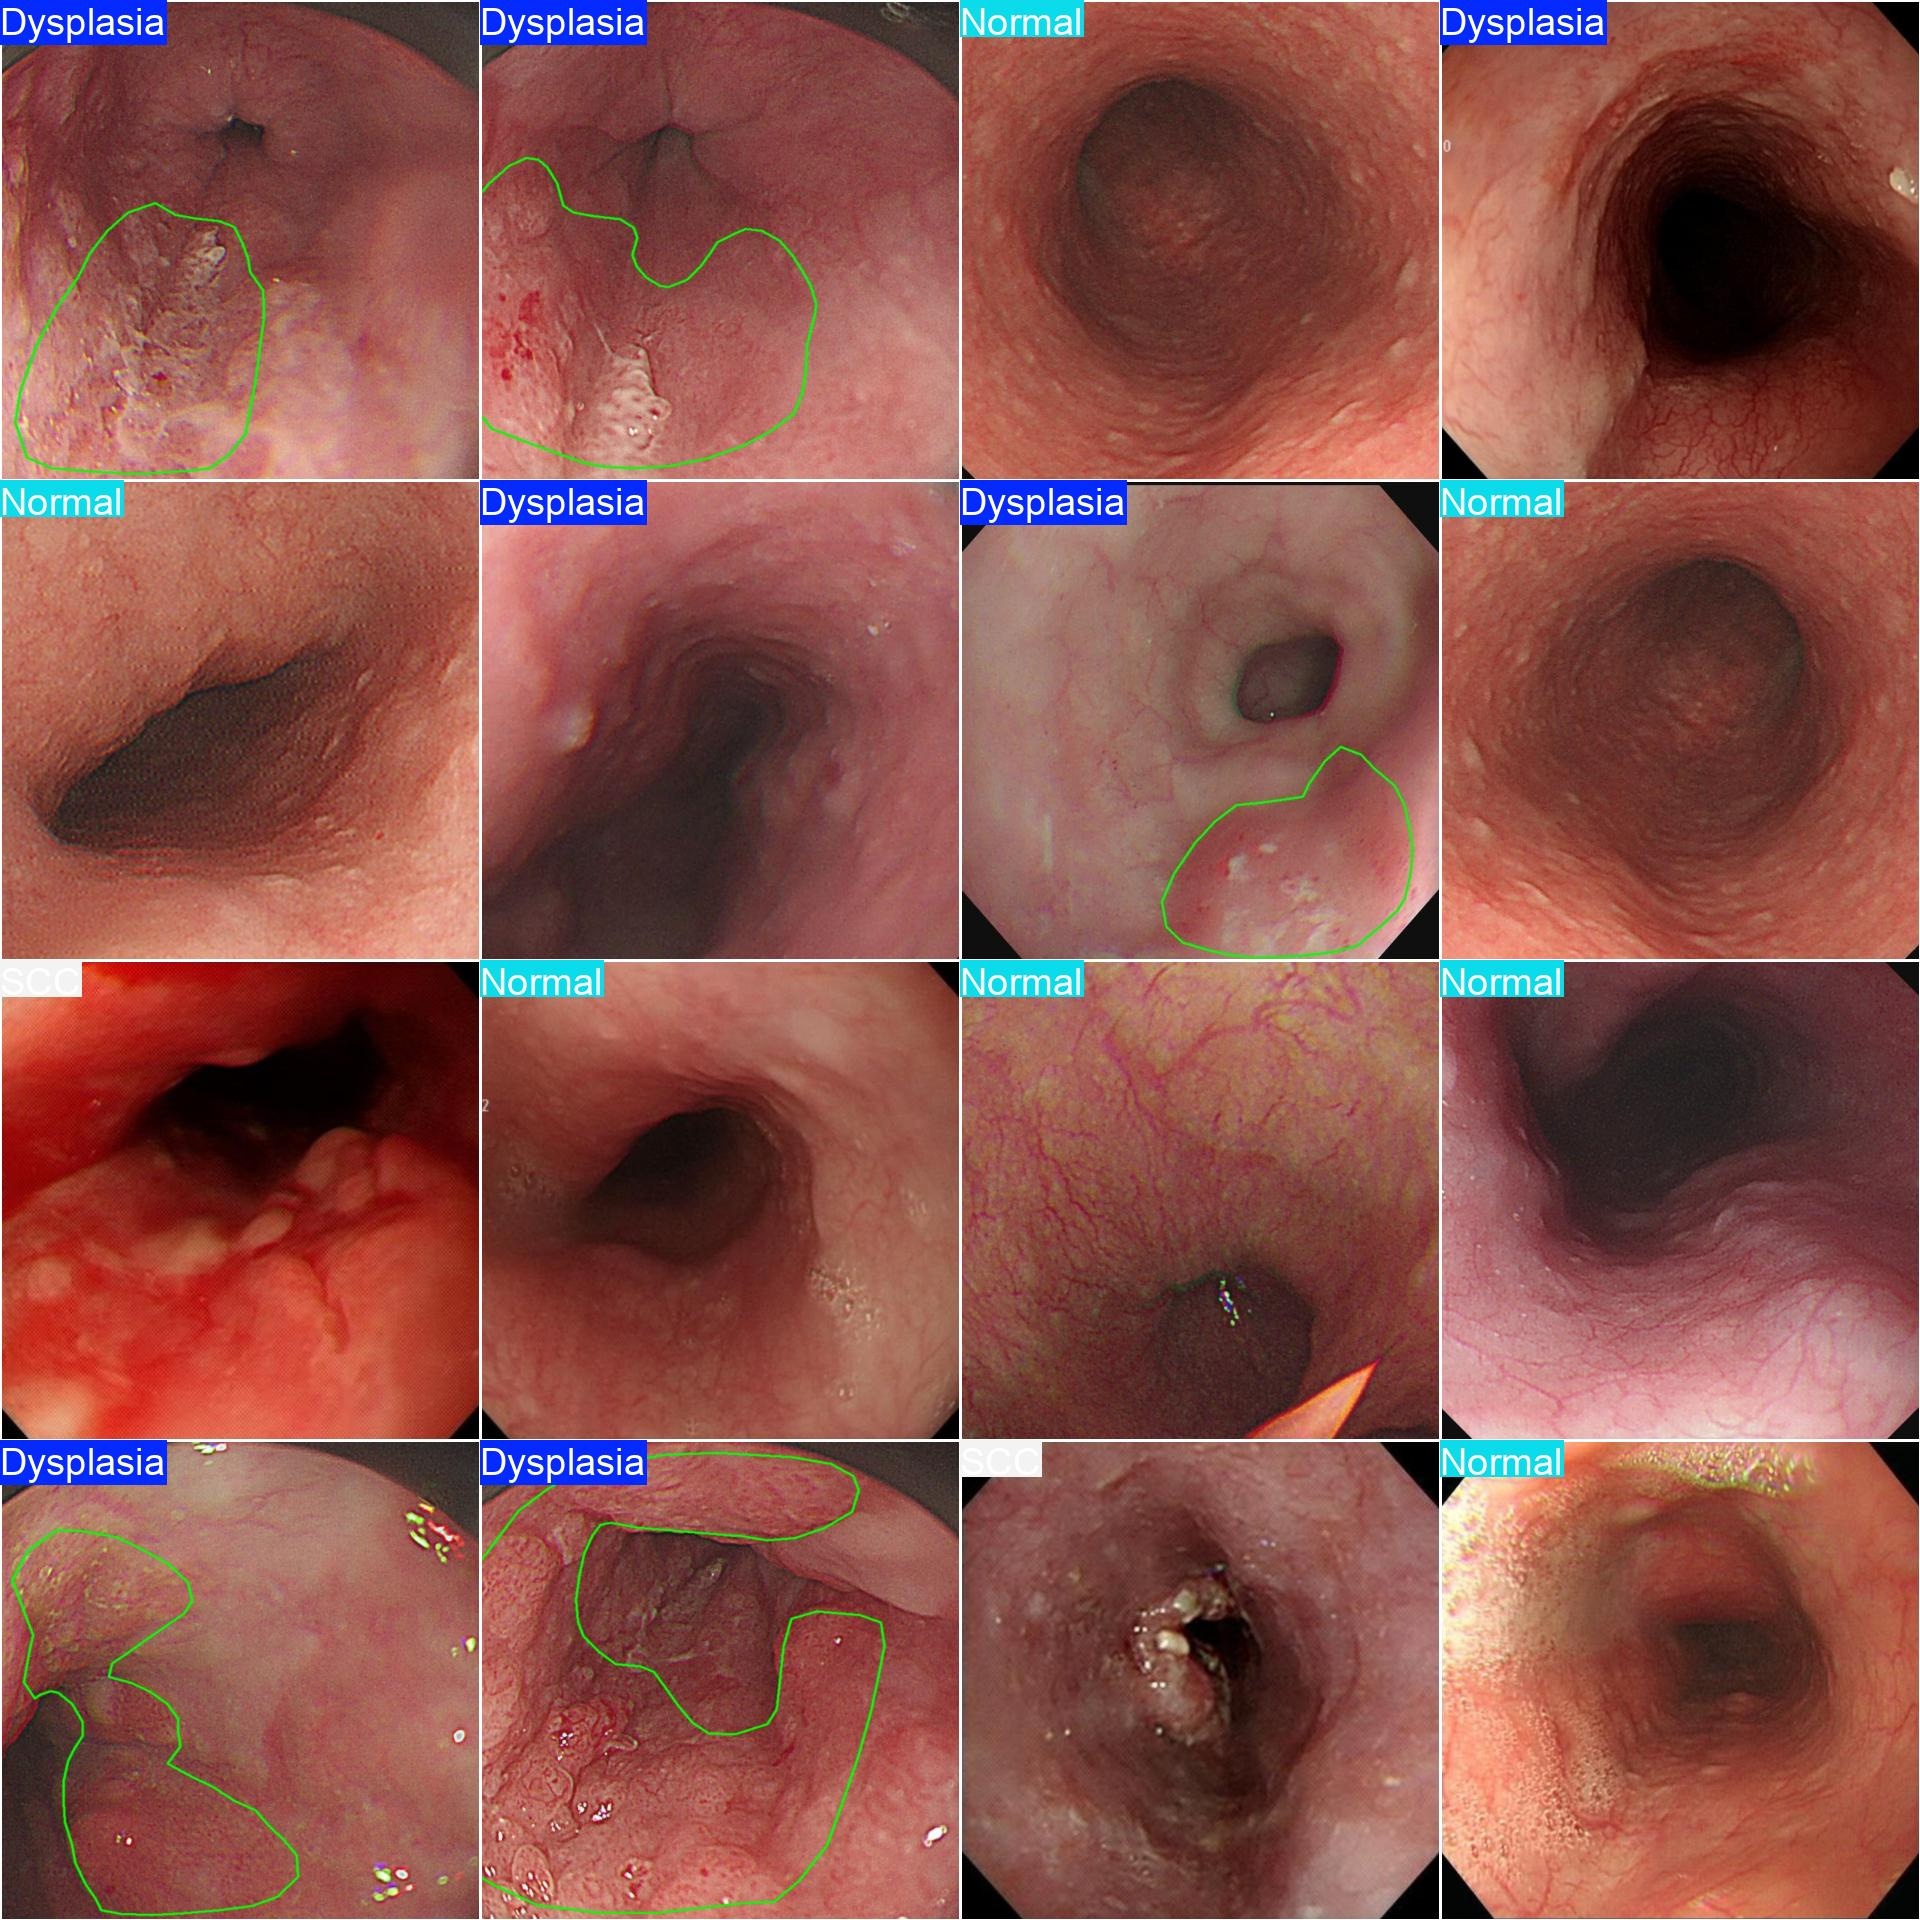

In [ ]:
Image(filename='/content/drive/MyDrive/new_dataset_EC/ec/EC/WLI_split/test_runs/300_test_n/val_batch0_pred.jpg', width=1000, height=700)


In [ ]:
import os
# Directory for your WLI data
DATA_DIR = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC/CA090.jpg'

model_wli= '/content/drive/MyDrive/new_dataset_EC/ec/EC/final/YOLOv8/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt'


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

image 1/1 /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC/CA090.jpg: 640x640 Dysplasia 0.61, SCC 0.39, Normal 0.00, 3.9ms
Speed: 188.4ms preprocess, 3.9ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)


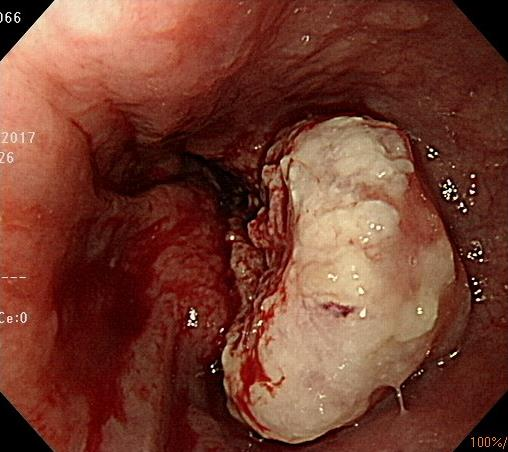

In [ ]:

import os
from ultralytics import YOLO
from IPython.display import Image, display

# Path to your saved model
model_path = '/content/drive/MyDrive/new_dataset_EC/ec/EC/final/YOLOv8/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt'

# Load your saved model
model = YOLO(model_path)

# Path to your test image
test_image_path = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC/CA090.jpg'

# Define class names (replace with your actual class names)
class_names = ['Dysplasia', 'Normal', 'SCC']

# Function to get true label (replace with your logic to extract true label from filename or other source)
def get_true_label(image_file):
    # Example: Assuming the image filename contains the true label as a prefix
    return image_file.split('/')[-2]

if os.path.isfile(test_image_path):
    try:
        results = model(test_image_path)
        display(Image(filename=test_image_path, width=300))

        for result in results:
            boxes = result.boxes
            if boxes:
                for r in boxes.data.tolist():
                    conf = r[4]
                    pred_class = int(r[5])
                    pred_label = class_names[pred_class]

                    true_label = get_true_label(test_image_path)
                    print(f"Confidence: {conf:.2f}, Predicted Label: {pred_label}, True Label: {true_label}")

    except Exception as e:
        print(f"Error processing {test_image_path}: {e}")
else:
    print(f"Test image not found: {test_image_path}")


In [ ]:
from google.colab import drive
import os
from IPython.display import Image, display
from ultralytics import YOLO
from sklearn.metrics import classification_report
import numpy as np
import os
from ultralytics import YOLO
from IPython.display import Image, display

In [ ]:

true_labels = []
pred_labels = []

# Path to your saved model
model_path = '/content/drive/MyDrive/new_dataset_EC/ec/EC/final/YOLOv8/WLI_split/runs/train_yolov8n-cls_300_epochs/weights/best.pt'

# Load your saved model
model = YOLO(model_path)

# Path to your test images directory
test_images_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/'

# Define class names (replace with your actual class names)
class_names = ['Dysplasia', 'Normal', 'SCC']

# Function to get true label (replace with your logic to extract true label from filename or other source)
def get_true_label(image_file):
    # Example: Assuming the image filename contains the true label as a prefix
    return image_file.split('/')[-2]


# Check if the directory exists
if not os.path.exists(test_images_dir):
    print(f"Test images directory not found: {test_images_dir}")

# Iterate over subdirectories and images
for class_dir in os.listdir(test_images_dir):
    class_path = os.path.join(test_images_dir, class_dir)
    # Check if it is a directory and not a file
    if os.path.isdir(class_path):
        for image_file in os.listdir(class_path):
            image_path = os.path.join(class_path, image_file)
            if os.path.isfile(image_path):
                try:
                    results = model(image_path)

                    for result in results:
                        boxes = result.boxes
                        if boxes:
                            for r in boxes.data.tolist():
                                conf = r[4]
                                pred_class = int(r[5])
                                pred_label = class_names[pred_class]
                                true_label = get_true_label(image_path)

                                # Store the true and predicted labels
                                true_labels.append(true_label)
                                pred_labels.append(pred_label)

                                print(f"True Label: {true_label}, Predicted Label: {pred_label}")

                except Exception as e:
                    print(f"Error processing {image_path}: {e}")
    else:
        print(f"Skipping non-directory entry: {class_path}")




image 1/1 /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/Dysplasia/041_REC20201028-142739156_ 02781.jpg: 640x640 SCC 0.71, Dysplasia 0.29, Normal 0.00, 3.6ms
Speed: 90.6ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/Dysplasia/146.jpg: 640x640 Dysplasia 1.00, Normal 0.00, SCC 0.00, 3.6ms
Speed: 25.6ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/Dysplasia/132.jpg: 640x640 Dysplasia 1.00, SCC 0.00, Normal 0.00, 4.9ms
Speed: 24.1ms preprocess, 4.9ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/Dysplasia/111.jpg: 640x640 Dysplasia 1.00, SCC 0.00, Normal 0.00, 3.5ms
Speed: 20.8ms pr